# Executive Summary — Olist E-commerce Analysis

## Project Objective

Analyze Olist's Brazilian e-commerce data to evaluate sales performance, customer behavior, delivery reliability, seller performance, customer satisfaction, and payment patterns.

## Key Business Questions

1. Which product categories and regions contribute most to delivered-order revenue?
2. How do delivery delays relate to customer review scores?
3. How does repeat-customer behavior compare with one-time purchasing?
4. Which sellers have the highest and lowest observed late-order rates?
5. Which payment methods and installment options contribute most to payment value?

## Analysis Scope

The analysis combines order, order-item, product, customer, seller, review, and payment datasets. Revenue and payment records are aggregated separately where necessary to avoid double-counting caused by one-to-many relationships.

*Detailed findings and business recommendations will be added after the final validation of project metrics.*

## Table of Contents

1. Project Overview
2. Data Loading and Understanding
3. Data Quality Checks
4. Order and Delivery Performance
5. Revenue and Financial Reconciliation
6. Monthly Sales Trends
7. Product Category Analysis
8. Customer Behavior and Retention
9. Geographic Performance
10. Reviews and Customer Satisfaction
11. Seller Performance
12. Payment Methods and Installments
13. Final Business Insights and Recommendations

In [1]:
%pip install pandas numpy seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

print("Libraries loaded successfully.")


Libraries loaded successfully.


 ## 1. Define the data path

In [3]:
DATA_PATH = Path(r"E:\Olist Ecommerce\data\raw")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_PATH}")

print(f"Dataset path: {DATA_PATH}")
print(f"Path exists: {DATA_PATH.exists()}")


Dataset path: E:\Olist Ecommerce\data\raw
Path exists: True


 ## 2. Load all source datasets

In [4]:
customers = pd.read_csv(DATA_PATH / "olist_customers_dataset.csv")
geolocation = pd.read_csv(DATA_PATH / "olist_geolocation_dataset.csv")
order_items = pd.read_csv(DATA_PATH / "olist_order_items_dataset.csv")
order_payments = pd.read_csv(DATA_PATH / "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(DATA_PATH / "olist_order_reviews_dataset.csv")
orders = pd.read_csv(DATA_PATH / "olist_orders_dataset.csv")
products = pd.read_csv(DATA_PATH / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_PATH / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(DATA_PATH / "product_category_name_translation.csv")

print("All 9 datasets loaded successfully.")


All 9 datasets loaded successfully.


In [5]:
datasets = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "order_payments": order_payments,
    "order_reviews": order_reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation,
}


 ## 3. Initial inspection

In [6]:
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


customers: 99,441 rows × 5 columns
geolocation: 1,000,163 rows × 5 columns
order_items: 112,650 rows × 7 columns
order_payments: 103,886 rows × 5 columns
order_reviews: 99,224 rows × 7 columns
orders: 99,441 rows × 8 columns
products: 32,951 rows × 9 columns
sellers: 3,095 rows × 4 columns
category_translation: 71 rows × 2 columns


In [7]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)
    print(df.columns.tolist())



CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

GEOLOCATION
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

ORDER_ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

ORDER_PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

ORDER_REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_heigh

In [8]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)
    print(df.dtypes)



CUSTOMERS
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

GEOLOCATION
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

ORDER_ITEMS
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

ORDER_PAYMENTS
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

ORDER_REVIEWS
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
re

 ## 4. Missing-value and duplicate assessment

In [9]:
missing_summary = {}

for name, df in datasets.items():
    missing_count = df.isna().sum()
    missing_pct = (missing_count / len(df) * 100).round(2)

    summary = pd.DataFrame({
        "missing_count": missing_count,
        "missing_percentage": missing_pct,
    })
    summary = summary[summary["missing_count"] > 0].sort_values(
        "missing_count", ascending=False
    )
    missing_summary[name] = summary

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)
    display(summary)



CUSTOMERS


,missing_count,missing_percentage



GEOLOCATION


,missing_count,missing_percentage



ORDER_ITEMS


...

,missing_count,missing_percentage
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



SELLERS


,missing_count,missing_percentage



CATEGORY_TRANSLATION


,missing_count,missing_percentage


In [10]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum():,} duplicate rows")


customers: 0 duplicate rows
geolocation: 261,831 duplicate rows
order_items: 0 duplicate rows
order_payments: 0 duplicate rows
order_reviews: 0 duplicate rows
orders: 0 duplicate rows
products: 0 duplicate rows
sellers: 0 duplicate rows
category_translation: 0 duplicate rows


 ## 5. Convert order timestamps before date analysis



 `read_csv` initially imports these timestamp columns as strings. Convert them

 before subtracting dates. Invalid values, if any, become `NaT` and should be

 investigated rather than silently imputed.

In [11]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

display(orders[date_columns].dtypes)
display(orders[date_columns].isna().sum().rename("missing_after_conversion"))


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
Name: missing_after_conversion, dtype: int64

 ## 6. Investigate missing order timestamps by order status

In [12]:
for col in [
    "order_delivered_customer_date",
    "order_delivered_carrier_date",
    "order_approved_at",
]:
    print(f"\nMissing {col} by order status:")
    display(
        orders.loc[orders[col].isna(), "order_status"]
        .value_counts(dropna=False)
    )



Missing order_delivered_customer_date by order status:


order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


Missing order_delivered_carrier_date by order status:


order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64


Missing order_approved_at by order status:


order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

 ## 7. Create a meaningful order delivery classification



 Keep the original `order_status`; this additional column groups statuses for

 reporting without treating every undelivered order as the same outcome.

In [13]:
orders["delivery_status"] = np.select(
    [
        orders["order_status"].eq("delivered"),
        orders["order_status"].isin(["canceled", "unavailable"]),
        orders["order_status"].isin(
            ["shipped", "invoiced", "processing", "approved", "created"]
        ),
    ],
    ["Delivered", "Canceled/Unavailable", "In Progress"],
    default="Other",
)

display(orders["delivery_status"].value_counts(dropna=False))


delivery_status
Delivered               96478
In Progress              1729
Canceled/Unavailable     1234
Name: count, dtype: int64

 ## 8. Clean review comment fields



 Use an explicit label for absent text. This does not imply the customer

 actually wrote the words "No comment."

In [14]:
review_comment_columns = ["review_comment_title", "review_comment_message"]

for col in review_comment_columns:
    order_reviews[col] = order_reviews[col].fillna("No comment")

display(order_reviews[review_comment_columns].isna().sum())


review_comment_title      0
review_comment_message    0
dtype: int64

 ## 9. Translate product categories and standardize column names

In [15]:
products = products.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one",
)

products.rename(
    columns={
        "product_category_name_english": "product_category",
        "product_name_lenght": "product_name_length",
        "product_description_lenght": "product_description_length",
    },
    inplace=True,
)

products["product_category"] = products["product_category"].fillna("Unknown")

display(
    products.loc[
        products["product_category"].eq("Unknown"),
        [
            "product_id",
            "product_category",
            "product_name_length",
            "product_description_length",
            "product_photos_qty",
        ],
    ].head(20)
)


,product_id,product_category,product_name_length,product_description_length,product_photos_qty
105,a41e356c76fab66334f36de622ecbd3a,Unknown,NaN,NaN,NaN
128,d8dee61c2034d6d075997acef1870e9b,Unknown,NaN,NaN,NaN
145,56139431d72cd51f19eb9f7dae4d1617,Unknown,NaN,NaN,NaN
154,46b48281eb6d663ced748f324108c733,Unknown,NaN,NaN,NaN
197,5fb61f482620cb672f5e586bb132eae9,Unknown,NaN,NaN,NaN
244,e10758160da97891c2fdcbc35f0f031d,Unknown,NaN,NaN,NaN
294,39e3b9b12cd0bf8ee681bbc1c130feb5,Unknown,NaN,NaN,NaN
299,794de06c32a626a5692ff50e4985d36f,Unknown,NaN,NaN,NaN
347,7af3e2da474486a3519b0cba9dea8ad9,Unknown,NaN,NaN,NaN
428,629beb8e7317703dcc5f35b5463fd20e,Unknown,NaN,NaN,NaN


 ## 10. Inspect missing product dimensions



 Preserve missing dimensions. Do not fabricate physical measurements when

 they are not needed for the current analysis.

In [16]:
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

display(products.loc[products[dimension_columns].isna().any(axis=1), dimension_columns])


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,NaN,NaN,NaN,NaN
18851,NaN,NaN,NaN,NaN


 ## 11. Recheck missing values after cleaning

In [17]:
for name, df in {
    "orders": orders,
    "order_reviews": order_reviews,
    "products": products,
}.items():
    print("\n" + "=" * 50)
    print(name.upper())
    print("=" * 50)
    remaining_missing = df.isna().sum()
    display(remaining_missing[remaining_missing > 0].sort_values(ascending=False))



ORDERS


order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
dtype: int64


ORDER_REVIEWS


Series([], dtype: int64)


PRODUCTS


product_category_name         610
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

 Missing order dates and product dimensions can be legitimate. Review comment

 nulls were replaced with an explicit absence label. Interpret missingness

 according to its business meaning instead of imputing indiscriminately.

 ## 12. Engineer delivery metrics for delivered orders only



 `delivery_delay_days` is actual delivery date minus estimated delivery date:

 positive = late, negative = early, zero = on the estimated date.

In [18]:
delivered_mask = orders["order_status"].eq("delivered")

actual_delivery = orders["order_delivered_customer_date"]
purchase_date = orders["order_purchase_timestamp"]
estimated_delivery = orders["order_estimated_delivery_date"]

delivery_duration = (actual_delivery - purchase_date).dt.total_seconds() / 86400
delivery_delay = (actual_delivery - estimated_delivery).dt.total_seconds() / 86400

orders["delivery_days"] = delivery_duration.where(delivered_mask)
orders["delivery_delay_days"] = delivery_delay.where(delivered_mask)

print("Delivery metrics calculated.")
display(orders[["delivery_days", "delivery_delay_days"]].describe())


Delivery metrics calculated.


,delivery_days,delivery_delay_days
count,96470.000000,96470.000000
mean,12.558217,-11.178126
std,9.546156,10.184354
min,0.533414,-146.016123
25%,6.766204,-16.244065
50%,10.217477,-11.948102
75%,15.720182,-6.389815
max,209.628611,188.975081


 ## 13. Validate delivery metrics

In [19]:
print("Negative delivery durations:")
display(
    orders.loc[
        orders["delivery_days"] < 0,
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "delivery_days",
        ],
    ].head(20)
)

print("Delivered orders with missing actual delivery date:")
display(
    orders.loc[
        delivered_mask & actual_delivery.isna(),
        ["order_id", "order_status", "order_delivered_customer_date"],
    ].head(20)
)


Negative delivery durations:


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days


Delivered orders with missing actual delivery date:


,order_id,order_status,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,NaT
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,NaT
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,NaT
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,NaT
82868,0d3268bad9b086af767785e3f0fc0133,delivered,NaT
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,NaT
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,NaT
98038,20edc82cf5400ce95e1afacc25798b31,delivered,NaT


In [20]:
orders["delivery_performance"] = np.select(
    [
        orders["delivery_delay_days"] < 0,
        orders["delivery_delay_days"].eq(0),
        orders["delivery_delay_days"] > 0,
    ],
    ["Early", "On Time", "Late"],
    default="Unknown",
)

display(orders["delivery_performance"].value_counts(dropna=False))


delivery_performance
Early      88644
Late        7826
Unknown     2971
Name: count, dtype: int64

 ## 14. Final checkpoint



 Review these outputs before moving into joins, business analysis, SQL, and

 dashboard preparation.

In [21]:
print("Orders shape:", orders.shape)
print("Products shape:", products.shape)
print("Order timestamp dtypes:")
display(orders[date_columns].dtypes)
print("Delivery classification:")
display(orders["delivery_status"].value_counts(dropna=False))
print("Delivery performance:")
display(orders["delivery_performance"].value_counts(dropna=False))


Orders shape: (99441, 12)
Products shape: (32951, 10)
Order timestamp dtypes:


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Delivery classification:


delivery_status
Delivered               96478
In Progress              1729
Canceled/Unavailable     1234
Name: count, dtype: int64

Delivery performance:


delivery_performance
Early      88644
Late        7826
Unknown     2971
Name: count, dtype: int64

In [22]:
print("ORDERS:", orders.shape)
print("PRODUCTS:", products.shape)

print("\nDATE TYPES:")
display(orders[date_columns].dtypes)

print("\nDELIVERY STATUS:")
display(orders["delivery_status"].value_counts())

print("\nDELIVERY PERFORMANCE:")
display(orders["delivery_performance"].value_counts())

print("\nDELIVERY METRICS:")
display(
    orders[
        ["delivery_days", "delivery_delay_days"]
    ].describe()
)

ORDERS: (99441, 12)
PRODUCTS: (32951, 10)

DATE TYPES:


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


DELIVERY STATUS:


delivery_status
Delivered               96478
In Progress              1729
Canceled/Unavailable     1234
Name: count, dtype: int64


DELIVERY PERFORMANCE:


delivery_performance
Early      88644
Late        7826
Unknown     2971
Name: count, dtype: int64


DELIVERY METRICS:


,delivery_days,delivery_delay_days
count,96470.000000,96470.000000
mean,12.558217,-11.178126
std,9.546156,10.184354
min,0.533414,-146.016123
25%,6.766204,-16.244065
50%,10.217477,-11.948102
75%,15.720182,-6.389815
max,209.628611,188.975081


In [23]:
print("Negative delivery durations:",
      (orders["delivery_days"] < 0).sum())

print("Missing delivery durations:",
      orders["delivery_days"].isna().sum())

print("Duplicate order IDs:",
      orders["order_id"].duplicated().sum())

print("Duplicate product IDs:",
      products["product_id"].duplicated().sum())

Negative delivery durations: 0
Missing delivery durations: 2971
Duplicate order IDs: 0
Duplicate product IDs: 0


 9,441 orders: the order dataset has the expected Olist dataset size.

 32,951 products: Product records loaded successfully.

 Zero negative delivery durations: No delivered order currently has a negative calculated delivery duration.

 Zero duplicate IDs: The order and product identifiers are unique in their respective tables.

 2,971 missing delivery durations: This is not automatically a problem. It may represent orders that were canceled, unavailable, or never completed.

In [24]:
print("DATETIME TYPES")
display(orders[date_columns].dtypes)

print("\nDELIVERY STATUS")
display(orders["delivery_status"].value_counts())

print("\nDELIVERY PERFORMANCE")
display(orders["delivery_performance"].value_counts())

print("\nORDER STATUS")
display(orders["order_status"].value_counts())

DATETIME TYPES


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


DELIVERY STATUS


delivery_status
Delivered               96478
In Progress              1729
Canceled/Unavailable     1234
Name: count, dtype: int64


DELIVERY PERFORMANCE


delivery_performance
Early      88644
Late        7826
Unknown     2971
Name: count, dtype: int64


ORDER STATUS


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [25]:
orders[
    orders["delivery_days"].isna()
]["order_status"].value_counts()

order_status
shipped        1107
canceled        625
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

 Early deliveries 88,644
 Late deliveries 7,826
 Unknown 2,971

The 8 delivered orders deserve attention because they may have missing actual delivery dates.

In [26]:
# Inspect delivered orders with missing delivery duration

missing_delivered = orders[
    (orders["order_status"] == "delivered") &
    (orders["delivery_days"].isna())
]

print("Delivered orders with missing delivery duration:",
      len(missing_delivered))

display(
    missing_delivered[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "delivery_days",
            "delivery_performance"
        ]
    ]
)

Delivered orders with missing delivery duration: 8


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_performance
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,NaT,2017-12-18,NaN,Unknown
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,NaT,2018-07-16,NaN,Unknown
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,NaT,2018-07-30,NaN,Unknown
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,NaT,2018-07-30,NaN,Unknown
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,NaT,2018-07-24,NaN,Unknown
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,NaT,2017-06-23,NaN,Unknown
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,NaT,2018-06-26,NaN,Unknown
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,NaT,2018-07-19,NaN,Unknown


This is a data quality issue not a calculation error.

my handling is correct:

i will keep the original records.

i will leave delivery_days as NaN.

i will classify delivery performance as Unknown.

i will NOT invent delivery durations or replace them with zero.

In [27]:
# %% ORDERS BUSINESS KPIs

total_orders = orders["order_id"].nunique()

delivered_orders = (
    orders["order_status"] == "delivered"
).sum()

canceled_orders = (
    orders["order_status"] == "canceled"
).sum()

delivery_rate = (
    delivered_orders / total_orders
) * 100

cancellation_rate = (
    canceled_orders / total_orders
) * 100

avg_delivery_days = orders["delivery_days"].mean()

print("========== ORDER KPIs ==========")

print(f"Total Orders: {total_orders:,}")
print(f"Delivered Orders: {delivered_orders:,}")
print(f"Canceled Orders: {canceled_orders:,}")

print(f"Delivery Rate: {delivery_rate:.2f}%")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

print(f"Average Delivery Time: {avg_delivery_days:.2f} days")

========== ORDER KPIs ==========
Total Orders: 99,441
Delivered Orders: 96,478
Canceled Orders: 625
Delivery Rate: 97.02%
Cancellation Rate: 0.63%
Average Delivery Time: 12.56 days


## Why i'm doing this

These are the first metrics I'll eventually use in Power BI

Total Orders = 99,441

Delivered Orders = 96,478

Delivery Rate = 97.02%

Cancellation Rate = 0.63%

Average Delivery Time = 12.56 days

The 97.02% delivery rate means delivered orders divided by all orders. It is a status-based rate, not necessarily a measure of successful customer experience.

Also, cancellation rate currently includes only canceled, not unavailable. I can report both separately later.

In [28]:
# %% REVENUE DATA INSPECTION

print("ORDER ITEMS")
print("Shape:", order_items.shape)
display(order_items.head())

print("\nORDER PAYMENTS")
print("Shape:", order_payments.shape)
display(order_payments.head())

print("\nORDER ITEMS MISSING VALUES")
display(order_items.isna().sum())

print("\nORDER PAYMENTS MISSING VALUES")
display(order_payments.isna().sum())

ORDER ITEMS
Shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



ORDER PAYMENTS
Shape: (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



ORDER ITEMS MISSING VALUES


order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


ORDER PAYMENTS MISSING VALUES


order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

112,650 order-item records

103,886 payment records

Zero missing values in either table.

the number of item records is greater than the number of orders because a single order can contain multiple products.

In [29]:
# %% ORDER-LEVEL FINANCIAL AGGREGATION

# 1. Aggregate product items by order
items_agg = (
    order_items
    .groupby("order_id")
    .agg(
        total_items=("order_item_id", "count"),
        item_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum")
    )
    .reset_index()
)

# 2. Aggregate payments by order
payments_agg = (
    order_payments
    .groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum"),
        payment_records=("payment_sequential", "count")
    )
    .reset_index()
)

# 3. Merge aggregated tables with orders
financial_orders = (
    orders
    .merge(items_agg, on="order_id", how="left", validate="one_to_one")
    .merge(payments_agg, on="order_id", how="left", validate="one_to_one")
)

# 4. Calculate total order value from item and freight amounts
financial_orders["order_total"] = (
    financial_orders["item_revenue"] +
    financial_orders["freight_revenue"]
)

print("Financial Orders Shape:", financial_orders.shape)

display(
    financial_orders[
        [
            "order_id",
            "order_status",
            "total_items",
            "item_revenue",
            "freight_revenue",
            "order_total",
            "payment_total"
        ]
    ].head(10)
)

Financial Orders Shape: (99441, 18)


,order_id,order_status,total_items,item_revenue,freight_revenue,order_total,payment_total
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,1.0,29.99,8.72,38.71,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,1.0,118.70,22.76,141.46,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,1.0,159.90,19.22,179.12,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,1.0,45.00,27.20,72.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,1.0,19.90,8.72,28.62,28.62
5,a4591c265e18cb1dcee52889e2d8acc3,delivered,1.0,147.90,27.36,175.26,175.26
6,136cce7faa42fdb2cefd53fdc79a6098,invoiced,1.0,49.90,16.05,65.95,65.95
7,6514b8ad8028c9f2cc2374ded245783f,delivered,1.0,59.99,15.17,75.16,75.16
8,76c6e866289321a7c93b82b54852dc33,delivered,1.0,19.90,16.05,35.95,35.95
9,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,1.0,149.99,19.77,169.76,169.76


We now have one row per order, rather than one row per item or payment transaction.

That allows us to calculate financial metrics without multiplying revenue accidentally.

In [30]:
# %% FINANCIAL DATA VALIDATION

print("Original orders:", orders["order_id"].nunique())

print("Financial orders:", financial_orders["order_id"].nunique())

print("Duplicate order IDs:", financial_orders["order_id"].duplicated().sum())

print("\nMissing financial values:")

display(
    financial_orders[
        [
            "total_items",
            "item_revenue",
            "freight_revenue",
            "payment_total"
        ]
    ].isna().sum()
)

print("\nFinancial totals:")

print(f"Item Revenue: {financial_orders['item_revenue'].sum():,.2f}")
print(f"Freight Revenue: {financial_orders['freight_revenue'].sum():,.2f}")
print(f"Order Total: {financial_orders['order_total'].sum():,.2f}")
print(f"Payment Total: {financial_orders['payment_total'].sum():,.2f}")

Original orders: 99441
Financial orders: 99441
Duplicate order IDs: 0

Missing financial values:


total_items        775
item_revenue       775
freight_revenue    775
payment_total        1
dtype: int64


Financial totals:
Item Revenue: 13,591,643.70
Freight Revenue: 2,251,909.54
Order Total: 15,843,553.24
Payment Total: 16,008,872.12


Payment reconciliation difference

R$ 165,318.88

Payment total exceeds item + freight total by approximately 1.04%.

In [31]:
# %% INVESTIGATE MISSING FINANCIAL RECORDS

missing_items = financial_orders[
    financial_orders["item_revenue"].isna()
]

print("Orders without item records:", len(missing_items))

print("\nOrder status distribution:")

display(missing_items["order_status"].value_counts())

print("\nMissing item orders with payment records:")

display(
    missing_items[
        [
            "order_id",
            "order_status",
            "payment_total",
            "order_purchase_timestamp"
        ]
    ].head(15)
)

Orders without item records: 775

Order status distribution:


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


Missing item orders with payment records:


,order_id,order_status,payment_total,order_purchase_timestamp
266,8e24261a7e58791d10cb1bf9da94df5c,unavailable,84.00,2017-11-16 15:09:28
586,c272bcd21c287498b4883c7512019702,unavailable,97.68,2018-01-31 11:31:37
687,37553832a3a89c9b2db59701c357ca67,unavailable,132.46,2017-08-14 17:38:02
737,d57e15fb07fd180f06ab3926b39edcd2,unavailable,134.38,2018-01-08 19:39:03
1130,00b1cb0320190ca0daa2c88b35206009,canceled,0.00,2018-08-28 15:26:39
1160,2f634e2cebf8c0283e7ef0989f77d217,unavailable,615.53,2017-09-27 20:55:33
1579,ee0db22a8e742b752914016708470ec8,unavailable,167.82,2017-08-24 11:04:41
1801,ed3efbd3a87bea76c2812c66a0b32219,canceled,191.46,2018-09-20 13:54:16
1826,6ad57aecbae806a7e9cc2cdb6b380711,unavailable,161.47,2017-11-30 07:48:24
1868,df8282afe61008dc26c6c31011474d02,canceled,139.96,2017-03-04 12:14:30


In [32]:
# %% INVESTIGATE PAYMENT MISSINGNESS

missing_payments = financial_orders[
    financial_orders["payment_total"].isna()
]

display(
    missing_payments[
        [
            "order_id",
            "order_status",
            "item_revenue",
            "freight_revenue",
            "order_total"
        ]
    ]
)

,order_id,order_status,item_revenue,freight_revenue,order_total
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,134.97,8.49,143.46


Imagine an order was canceled before any product shipment.

It may have no item record, and treating it as a completed sale would distort our analysis!!

We should not assume those payments were retained revenue or successfully refunded without additional evidence.

In [33]:
# %% PAYMENT RECONCILIATION

financial_orders["payment_difference"] = (
    financial_orders["payment_total"] -
    financial_orders["order_total"]
)

reconciliation = financial_orders[
    financial_orders["payment_total"].notna() &
    financial_orders["order_total"].notna()
].copy()

reconciliation["reconciliation_status"] = np.select(
    [
        reconciliation["payment_difference"].abs() <= 0.01,
        reconciliation["payment_difference"] > 0.01,
        reconciliation["payment_difference"] < -0.01
    ],
    [
        "Matched",
        "Payment Higher",
        "Payment Lower"
    ],
    default="Other"
)

print("Reconciliation Results:")

display(
    reconciliation["reconciliation_status"].value_counts()
)

print("\nAverage payment difference:")
print(reconciliation["payment_difference"].mean())

print("\nLargest positive differences:")

display(
    reconciliation.sort_values(
        "payment_difference",
        ascending=False
    )[
        [
            "order_id",
            "order_status",
            "order_total",
            "payment_total",
            "payment_difference"
        ]
    ].head(10)
)

Reconciliation Results:


reconciliation_status
Matched           98284
Payment Higher      291
Payment Lower        90
Name: count, dtype: int64


Average payment difference:
0.029092281964221974

Largest positive differences:


,order_id,order_status,order_total,payment_total,payment_difference
11791,ce6d150fb29ada17d2082f4847107665,delivered,1403.66,1586.47,182.81
48686,6e5fe7366a2e1bfbf3257dba0af1267f,delivered,287.91,406.92,119.01
70865,70b742795bc441e94a44a084b6d9ce7a,delivered,466.93,578.82,111.89
33150,996c7e73600ad3723e8627ab7bef81e4,delivered,587.90,664.43,76.53
52985,70b7e94ea46d3e8b5bc12a50186edaf0,delivered,213.15,274.84,61.69
85434,bc2c82b0ef78d2252b6176d1972db7c9,delivered,242.01,303.02,61.01
94304,af9ffff2ce6b3defd34fd4c78857a379,delivered,413.17,466.97,53.80
68811,bfdb5bbb06458d600a33d61f5f287472,delivered,348.93,394.36,45.43
8548,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,delivered,254.45,293.89,39.44
2615,b7579d24f5b2dd3e20f2e57d0e07d170,delivered,466.28,504.37,38.09


The average difference is approximately R$0.03 per compared order, but that average hides some larger discrepancies.

For example, one delivered order has a payment difference of R$182.81.

We should investigate these rather than automatically treating payment totals as revenue.

One important possibility is that an order has multiple payment records, such as a voucher plus a credit-card payment, or installments. We already aggregated all payment records by order, so let's inspect the underlying transactions.

In [34]:
# %% INVESTIGATE PAYMENT-HIGHER ORDERS

higher_orders = reconciliation[
    reconciliation["payment_difference"] > 0.01
].copy()

higher_ids = higher_orders["order_id"]

higher_payment_details = order_payments[
    order_payments["order_id"].isin(higher_ids)
].sort_values(
    ["order_id", "payment_sequential"]
)

print("Orders with higher payment:", len(higher_orders))

print("Payment records for these orders:",
      len(higher_payment_details))

print("\nPayment types:")

display(
    higher_payment_details["payment_type"].value_counts()
)

print("\nPayment record count per order:")

display(
    higher_payment_details.groupby("order_id")
    .size()
    .value_counts()
    .sort_index()
)

print("\nLargest discrepancies with payment details:")

display(
    higher_orders[
        [
            "order_id",
            "order_total",
            "payment_total",
            "payment_difference"
        ]
    ].head(10).merge(
        higher_payment_details,
        on="order_id",
        how="left"
    )
)

Orders with higher payment: 291
Payment records for these orders: 310

Payment types:


payment_type
credit_card    285
boleto          16
voucher          8
debit_card       1
Name: count, dtype: int64


Payment record count per order:


1    272
2     19
Name: count, dtype: int64


Largest discrepancies with payment details:


,order_id,order_total,payment_total,payment_difference,payment_sequential,payment_type,payment_installments,payment_value
0,84d6d9710c8af32b5e88f2d1c14ab871,57.68,61.70,4.02,1,credit_card,5,61.70
1,74016effecaa79d592487f6a4ee47d4b,51.51,56.96,5.45,1,credit_card,5,56.96
2,239f380355f65dcb68551f07d16fc4a8,222.63,251.63,29.00,1,credit_card,10,251.63
3,4c57f545143e8865ca2347d8cba154a7,139.61,151.01,11.40,1,credit_card,6,151.01
4,b38b3526b8b8fdc807e8a0a42ab78573,30.06,30.19,0.13,1,credit_card,2,26.28
5,b38b3526b8b8fdc807e8a0a42ab78573,30.06,30.19,0.13,2,credit_card,1,3.91
6,8b5058499c412c6cf8d013de40e4f9d2,48.77,51.02,2.25,1,credit_card,3,51.02
7,b7579d24f5b2dd3e20f2e57d0e07d170,466.28,504.37,38.09,1,credit_card,6,504.37
8,8b7fd198ad184563c231653673e75a7f,49.33,56.97,7.64,1,credit_card,5,56.97
9,3b773756d8fc59a7cd1a0c4ac584e397,167.17,188.96,21.79,1,credit_card,10,188.96


The 291 orders with higher payments have 310 payment records:

272 orders have one payment record.

19 orders have two payment records.

Credit card accounts for 285 of the 310 records.

The two-payment example confirms that my aggregation correctly sums multiple payment transactions. But multiple payment records do not explain all discrepancies: most of these orders have only one payment record.

We shouldn't assume the difference is an error or extra revenue without understanding the source.

In [35]:
# %% PAYMENT DIFFERENCE BY ORDER STATUS

display(
    reconciliation.groupby(
        ["order_status", "reconciliation_status"]
    ).agg(
        order_count=("order_id", "count"),
        avg_difference=("payment_difference", "mean"),
        total_difference=("payment_difference", "sum")
    ).round(2)
)

order_count  avg_difference  \
order_status reconciliation_status                                
approved     Matched                          2           -0.00   
canceled     Matched                        459           -0.00   
             Payment Higher                   2           16.01   
delivered    Matched                      96102           -0.00   
             Payment Higher                 286           10.60   
             Payment Lower                   89           -2.24   
invoiced     Matched                        311           -0.00   
             Payment Higher                   1            0.01   
processing   Matched                        301           -0.00   
shipped      Matched                       1103           -0.00   
             Payment Higher                   2            3.46   
             Payment Lower                    1           -0.01   
unavailable  Matched                          6            0.00   

                                    total_difference  
order_status reconciliation_status                    
approved     Matched                           -0.00  
canceled     Matched                           -0.00  
             Payment Higher                    32.01  
delivered    Matched                           -0.42  
             Payment Higher                  3031.48  
             Payment Lower                   -199.58  
invoiced     Matched                           -0.00  
             Payment Higher                     0.01  
processing   Matched                           -0.00  
shipped      Matched                           -0.01  
             Payment Higher                     6.91  
             Payment Lower                     -0.01  
unavailable  Matched                            0.00

In [36]:
# %% PAYMENT DIFFERENCE DISTRIBUTION

print("Payment Higher — Difference Summary")

display(
    higher_orders["payment_difference"].describe()
)

print("\nPayment Lower — Difference Summary")

lower_orders = reconciliation[
    reconciliation["payment_difference"] < -0.01
]

display(
    lower_orders["payment_difference"].describe()
)

Payment Higher — Difference Summary


count    291.000000
mean      10.551237
std       17.514328
min        0.010000
25%        1.875000
50%        5.550000
75%       12.140000
max      182.810000
Name: payment_difference, dtype: float64


Payment Lower — Difference Summary


count    90.000000
mean     -2.217667
std       6.784611
min     -51.620000
25%      -0.027500
50%      -0.010000
75%      -0.010000
max      -0.010000
Name: payment_difference, dtype: float64

The discrepancies are concentrated primarily among delivered orders.

The median payment-higher difference is R$5.55, while the maximum is R$182.81.

Overall difference between payment and item + freight totals

R$165,318.88

The reconciliation analysis excluded orders with missing item totals.

We already know that 775 orders have no item records, including 603 unavailable and 164 canceled orders.

Payments associated with those orders are a major area we need to investigate before interpreting the overall difference.

We should not label the entire difference as extra revenue.

In [37]:
# %% INVESTIGATE PAYMENTS WITHOUT ITEM RECORDS

missing_item_orders = financial_orders[
    financial_orders["item_revenue"].isna()
].copy()

print("Orders without item records:",
      len(missing_item_orders))

print("\nPayment totals for these orders:")

print(
    f"R$ {missing_item_orders['payment_total'].sum():,.2f}"
)

print("\nPayment totals by order status:")

display(
    missing_item_orders.groupby("order_status")
    .agg(
        order_count=("order_id", "count"),
        payment_total=("payment_total", "sum")
    )
    .sort_values("payment_total", ascending=False)
    .round(2)
)

Orders without item records: 775

Payment totals for these orders:
R$ 162,591.95

Payment totals by order status:


,order_count,payment_total
order_status,,
unavailable,603,124339.02
canceled,164,37337.87
created,5,688.10
invoiced,2,149.23
shipped,1,77.73


In [38]:
# %% RECONCILIATION ON ORDERS WITH BOTH FINANCIAL RECORDS

matched_financial = financial_orders[
    financial_orders["item_revenue"].notna() &
    financial_orders["payment_total"].notna()
].copy()

print("Orders with both item and payment records:",
      len(matched_financial))

print(
    "Item + Freight Total:",
    f"R$ {matched_financial['order_total'].sum():,.2f}"
)

print(
    "Payment Total:",
    f"R$ {matched_financial['payment_total'].sum():,.2f}"
)

print(
    "Net Difference:",
    f"R$ {matched_financial['payment_total'].sum() - matched_financial['order_total'].sum():,.2f}"
)

Orders with both item and payment records: 98665
Item + Freight Total: R$ 15,843,409.78
Payment Total: R$ 15,846,280.17
Net Difference: R$ 2,870.39


## This is a major milestone in the project.

Compare that with the original R$165,318.88 difference.

The 775 orders without item records account for R$162,591.95 in recorded payments.

However, we must not classify those payments as revenue just because payment records exist. Their order statuses include unavailable and canceled.

We now have three distinct financial populations:

Orders with items and payments 98,665  Reconciliation possible

Orders without item records 775 Investigate separately

Orders with missing payment 1 Preserve as missing


Our next step is to calculate business KPIs using a clearly defined population.

For the initial revenue analysis, we'll use delivered orders with valid item records, and report item revenue and freight separately.

In [39]:
# %% REVENUE KPI ANALYSIS

delivered_financial = financial_orders[
    (financial_orders["order_status"] == "delivered") &
    (financial_orders["item_revenue"].notna())
].copy()

total_delivered_revenue = delivered_financial["item_revenue"].sum()

total_delivered_freight = delivered_financial["freight_revenue"].sum()

total_delivered_order_value = delivered_financial["order_total"].sum()

delivered_order_count = delivered_financial["order_id"].nunique()

average_order_value = (
    total_delivered_revenue / delivered_order_count
)

average_order_total = (
    total_delivered_order_value / delivered_order_count
)

print("========== DELIVERED ORDER REVENUE KPIs ==========")

print(f"Delivered Orders: {delivered_order_count:,}")

print(f"Product Revenue: R$ {total_delivered_revenue:,.2f}")

print(f"Freight Revenue: R$ {total_delivered_freight:,.2f}")

print(f"Total Order Value: R$ {total_delivered_order_value:,.2f}")

print(f"Average Order Value (Products): R$ {average_order_value:,.2f}")

print(f"Average Order Value (Including Freight): R$ {average_order_total:,.2f}")

========== DELIVERED ORDER REVENUE KPIs ==========
Delivered Orders: 96,478
Product Revenue: R$ 13,221,498.11
Freight Revenue: R$ 2,198,275.64
Total Order Value: R$ 15,419,773.75
Average Order Value (Products): R$ 137.04
Average Order Value (Including Freight): R$ 159.83


Product Revenue: Total merchandise value from delivered orders.

Freight Revenue: Shipping charges associated with those orders.

Product AOV: Average merchandise value per delivered order.

Total Order Value: Merchandise plus freight, not company profit.

## Now we want to answer:

How did revenue change over time?

Which months generated the most sales?

Did order volume and revenue move together?

What was the monthly average order value?

In [40]:
# %% MONTHLY REVENUE ANALYSIS

delivered_financial["purchase_month"] = (
    delivered_financial["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_revenue = (
    delivered_financial
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique"),
        product_revenue=("item_revenue", "sum"),
        freight_revenue=("freight_revenue", "sum"),
        total_order_value=("order_total", "sum")
    )
    .reset_index()
)

monthly_revenue["product_aov"] = (
    monthly_revenue["product_revenue"] /
    monthly_revenue["orders"]
)

monthly_revenue["mom_revenue_change_pct"] = (
    monthly_revenue["product_revenue"]
    .pct_change() * 100
)

display(monthly_revenue.round(2))

,purchase_month,orders,product_revenue,freight_revenue,total_order_value,product_aov,mom_revenue_change_pct
0,2016-09,1,134.97,8.49,143.46,134.97,NaN
1,2016-10,265,40325.11,6165.55,46490.66,152.17,29777.09
2,2016-12,1,10.90,8.72,19.62,10.90,-99.97
3,2017-01,750,111798.36,15684.01,127482.37,149.06,1025573.03
4,2017-02,1653,234223.40,37015.92,271239.32,141.70,109.51
5,2017-03,2546,359198.85,55132.10,414330.95,141.08,53.36
6,2017-04,2303,340669.68,50142.72,390812.40,147.92,-5.16
7,2017-05,3546,489338.25,77513.15,566851.40,138.00,43.64
8,2017-06,3135,421923.37,68127.00,490050.37,134.58,-13.78
9,2017-07,3872,481604.52,84694.56,566299.08,124.38,14.15


This uses the purchase month, meaning sales are attributed to when customers placed their orders, even if delivery happened later.

In [41]:
# %% TOP REVENUE MONTHS

top_revenue_months = monthly_revenue.sort_values(
    "product_revenue",
    ascending=False
).head(10)

display(top_revenue_months.round(2))

,purchase_month,orders,product_revenue,freight_revenue,total_order_value,product_aov,mom_revenue_change_pct
13,2017-11,7289,987765.37,165598.83,1153364.20,135.51,52.37
19,2018-05,6749,977544.69,151229.83,1128774.52,144.84,0.41
18,2018-04,6798,973534.09,159344.84,1132878.93,143.21,2.12
17,2018-03,7003,953356.25,167241.99,1120598.24,136.14,15.36
15,2018-01,7069,924645.00,153242.46,1077887.46,130.80,27.36
21,2018-07,6159,867953.46,159853.82,1027807.28,140.92,1.39
20,2018-06,6099,856077.86,155900.43,1011978.29,140.36,-12.43
22,2018-08,6351,838576.64,146915.00,985491.64,132.04,-3.38
16,2018-02,6555,826437.13,139731.28,966168.41,126.08,-10.62
14,2017-12,5513,726033.19,117045.10,843078.29,131.69,-26.50



Highest revenue month November: 2017 - R$987,765.37

Highest order volume November: 2017 - 7,289 orders

Highest AOV in the displayed: period October 2016 - R$152.17, but only 265 orders

Strong growth period: 2017 through early 2018

Largest visible monthly decline: December 2017 - down 26.50%

2018 pattern: Revenue generally remained around R$800K-R$980K per month

November 2017 generated the highest product revenue in this dataset.

However, we should not immediately conclude that this was caused by Black Friday or a specific marketing campaign. We need additional evidence before making that attribution.

Also, your first months have extremely large MoM percentages because the starting months had very few orders. Those growth percentages are mathematically correct but should not be used as representative growth indicators.

dataset skips November 2016.

That means December 2016's MoM comparison is against October 2016, not November. We should create a complete monthly calendar and represent missing months as zero for the revenue time series.

This is useful because it prevents misleading month to month comparisons.

In [42]:
# %% COMPLETE MONTHLY TIMELINE

monthly_revenue["purchase_month"] = pd.to_datetime(
    monthly_revenue["purchase_month"]
)

monthly_revenue = (
    monthly_revenue
    .set_index("purchase_month")
    .asfreq("MS")
)

numeric_cols = [
    "orders",
    "product_revenue",
    "freight_revenue",
    "total_order_value"
]

monthly_revenue[numeric_cols] = (
    monthly_revenue[numeric_cols].fillna(0)
)

monthly_revenue["product_aov"] = np.where(
    monthly_revenue["orders"] > 0,
    monthly_revenue["product_revenue"] / monthly_revenue["orders"],
    np.nan
)

monthly_revenue["mom_revenue_change_pct"] = (
    monthly_revenue["product_revenue"].pct_change() * 100
)

monthly_revenue = monthly_revenue.reset_index()

monthly_revenue["purchase_month"] = (
    monthly_revenue["purchase_month"].dt.strftime("%Y-%m")
)

display(monthly_revenue.round(2))

,purchase_month,orders,product_revenue,freight_revenue,total_order_value,product_aov,mom_revenue_change_pct
0,2016-09,1.0,134.97,8.49,143.46,134.97,NaN
1,2016-10,265.0,40325.11,6165.55,46490.66,152.17,29777.09
2,2016-11,0.0,0.00,0.00,0.00,NaN,-100.00
3,2016-12,1.0,10.90,8.72,19.62,10.90,inf
4,2017-01,750.0,111798.36,15684.01,127482.37,149.06,1025573.03
5,2017-02,1653.0,234223.40,37015.92,271239.32,141.70,109.51
6,2017-03,2546.0,359198.85,55132.10,414330.95,141.08,53.36
7,2017-04,2303.0,340669.68,50142.72,390812.40,147.92,-5.16
8,2017-05,3546.0,489338.25,77513.15,566851.40,138.00,43.64
9,2017-06,3135.0,421923.37,68127.00,490050.37,134.58,-13.78


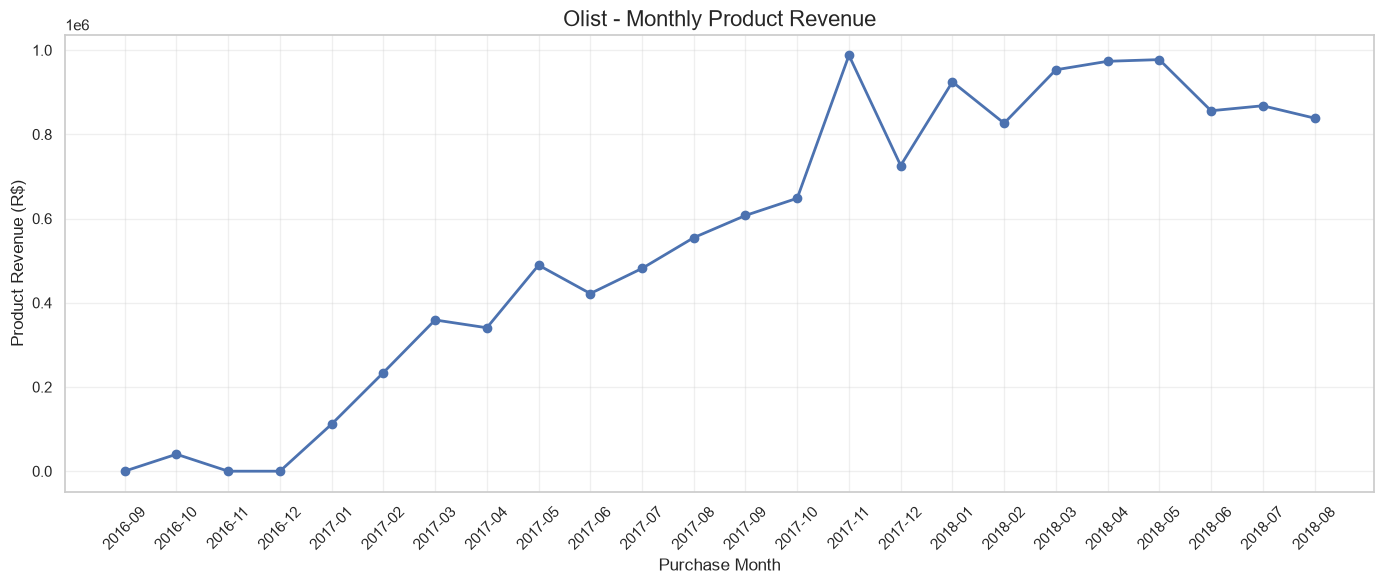

In [43]:
# %% MONTHLY REVENUE TREND

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["purchase_month"],
    monthly_revenue["product_revenue"],
    marker="o",
    linewidth=2
)

plt.title("Olist - Monthly Product Revenue", fontsize=16)
plt.xlabel("Purchase Month")
plt.ylabel("Product Revenue (R$)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

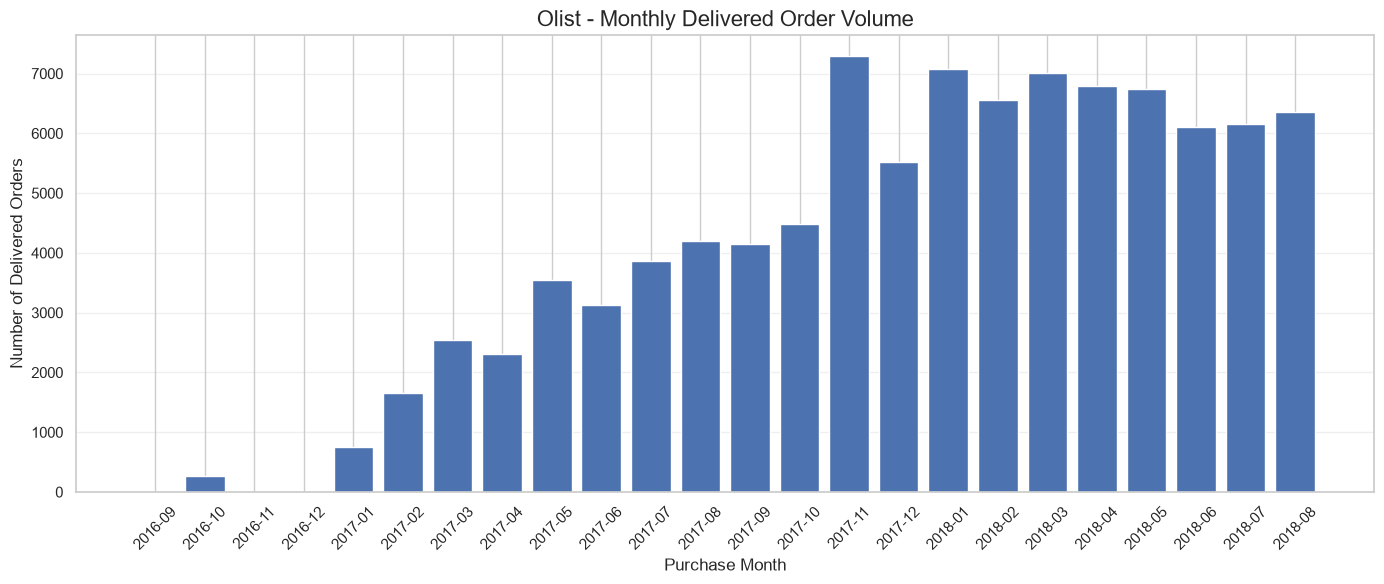

In [44]:
# %% MONTHLY ORDER VOLUME

plt.figure(figsize=(14, 6))

plt.bar(
    monthly_revenue["purchase_month"],
    monthly_revenue["orders"]
)

plt.title("Olist - Monthly Delivered Order Volume", fontsize=16)
plt.xlabel("Purchase Month")
plt.ylabel("Number of Delivered Orders")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Revenue trend

Revenue increased substantially throughout 2017.

November 2017 reached approximately R$987.8K, the highest monthly product revenue in the dataset.

December 2017 declined to approximately R$726K.

Revenue recovered in January 2018 and remained relatively high through May 2018.

June–August 2018 show a lower revenue range than the March–May period.

## Order volume

November 2017 recorded 7,289 delivered orders.

January 2018 recorded 7,069.

March 2018 recorded 7,003.

The 2018 order volume remained considerably higher than most of 2017.

## Initial business interpretation

Revenue and order volume generally move in the same direction. However, we need to investigate Average Order Value (AOV) to understand whether revenue changes are also associated with changes in customer spending per order.

We cannot establish the cause of these fluctuations from these two charts alone.

## November 2016 has zero orders, so AOV should be NaN, not zero. Also, percentage growth from a zero-revenue month is undefined, not infinity.

Let's fix that properly.

In [45]:
# %% FIX MONTHLY KPI CALCULATIONS

monthly_revenue["product_aov"] = np.where(
    monthly_revenue["orders"] > 0,
    monthly_revenue["product_revenue"] / monthly_revenue["orders"],
    np.nan
)

previous_revenue = monthly_revenue["product_revenue"].shift(1)

monthly_revenue["mom_revenue_change_pct"] = np.where(
    previous_revenue > 0,
    (
        (monthly_revenue["product_revenue"] - previous_revenue)
        / previous_revenue
    ) * 100,
    np.nan
)

display(monthly_revenue.round(2))

,purchase_month,orders,product_revenue,freight_revenue,total_order_value,product_aov,mom_revenue_change_pct
0,2016-09,1.0,134.97,8.49,143.46,134.97,NaN
1,2016-10,265.0,40325.11,6165.55,46490.66,152.17,29777.09
2,2016-11,0.0,0.00,0.00,0.00,NaN,-100.00
3,2016-12,1.0,10.90,8.72,19.62,10.90,NaN
4,2017-01,750.0,111798.36,15684.01,127482.37,149.06,1025573.03
5,2017-02,1653.0,234223.40,37015.92,271239.32,141.70,109.51
6,2017-03,2546.0,359198.85,55132.10,414330.95,141.08,53.36
7,2017-04,2303.0,340669.68,50142.72,390812.40,147.92,-5.16
8,2017-05,3546.0,489338.25,77513.15,566851.40,138.00,43.64
9,2017-06,3135.0,421923.37,68127.00,490050.37,134.58,-13.78


This prevents infinite growth percentages and avoids presenting an AOV for a month with no orders.

## Is revenue growth driven by order volume or AOV?

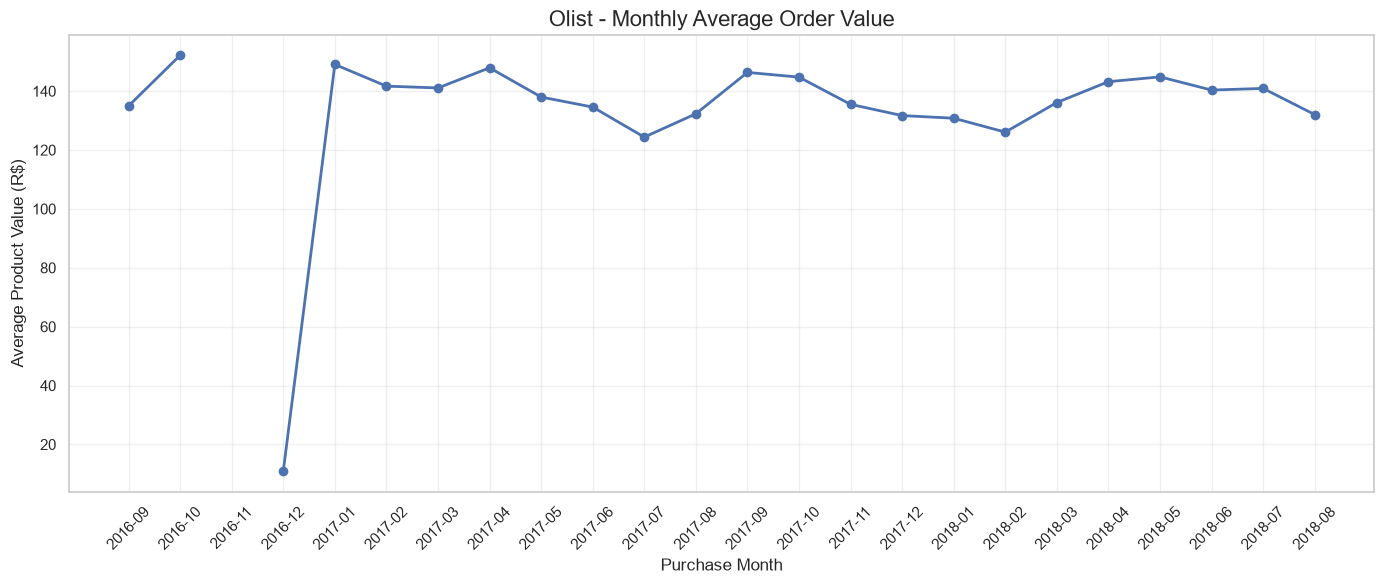

In [46]:
# %% MONTHLY AOV TREND

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["purchase_month"],
    monthly_revenue["product_aov"],
    marker="o",
    linewidth=2
)

plt.title("Olist - Monthly Average Order Value", fontsize=16)
plt.xlabel("Purchase Month")
plt.ylabel("Average Product Value (R$)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
# %% MONTHLY KPI COMPARISON

display(
    monthly_revenue[
        [
            "purchase_month",
            "orders",
            "product_revenue",
            "product_aov",
            "mom_revenue_change_pct"
        ]
    ].round(2)
)

,purchase_month,orders,product_revenue,product_aov,mom_revenue_change_pct
0,2016-09,1.0,134.97,134.97,NaN
1,2016-10,265.0,40325.11,152.17,29777.09
2,2016-11,0.0,0.00,NaN,-100.00
3,2016-12,1.0,10.90,10.90,NaN
4,2017-01,750.0,111798.36,149.06,1025573.03
5,2017-02,1653.0,234223.40,141.70,109.51
6,2017-03,2546.0,359198.85,141.08,53.36
7,2017-04,2303.0,340669.68,147.92,-5.16
8,2017-05,3546.0,489338.25,138.00,43.64
9,2017-06,3135.0,421923.37,134.58,-13.78


Revenue grew 52.37% in November compared with October, while AOV (Average Order Value) actually decreased from R$144.76 to R$135.51.

That suggests the revenue increase was primarily associated with the substantial increase in order volume rather than customers spending more per order.

This is an observed relationship, not proof of what caused the increase.

## Next phase: Product Category Performance

Now we're moving from when revenue happened to what generated revenue.

We want to answer:

Which product categories generate the most revenue?

Which categories attract the most orders?

Which categories have the highest average order value?

Are high-revenue categories also high-volume categories

In [48]:
# %% PRODUCT CATEGORY ANALYSIS

# Keep only delivered orders
delivered_order_ids = delivered_financial["order_id"].unique()

# Filter order items to delivered orders
delivered_items = order_items[
    order_items["order_id"].isin(delivered_order_ids)
].copy()

# Attach product category information
category_items = delivered_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Handle missing category labels
category_items["product_category_name"] = (
    category_items["product_category_name"]
    .fillna("unknown")
)

print("Delivered item records:", len(category_items))
print("Unique products:", category_items["product_id"].nunique())
print("Missing categories:", 
      category_items["product_category_name"].isna().sum())

display(category_items.head())

Delivered item records: 110197
Unique products: 32216
Missing categories: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [49]:
# %% CATEGORY REVENUE KPIs

category_performance = (
    category_items
    .groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        product_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

category_performance["revenue_per_order"] = (
    category_performance["product_revenue"] /
    category_performance["total_orders"]
)

category_performance["revenue_share_pct"] = (
    category_performance["product_revenue"] /
    category_performance["product_revenue"].sum()
) * 100

category_performance = category_performance.sort_values(
    "product_revenue",
    ascending=False
)

display(category_performance.head(15).round(2))

,product_category_name,total_orders,items_sold,product_revenue,freight_revenue,average_item_price,revenue_per_order,revenue_share_pct
11,beleza_saude,8647,9465,1233131.72,178957.81,130.28,142.61,9.33
66,relogios_presentes,5495,5859,1166176.98,98156.14,199.04,212.23,8.82
13,cama_mesa_banho,9272,10953,1023434.76,201774.50,93.44,110.38,7.74
32,esporte_lazer,7530,8431,954852.55,163404.36,113.25,126.81,7.22
44,informatica_acessorios,6530,7644,888724.61,143999.16,116.26,136.10,6.72
54,moveis_decoracao,6307,8160,711927.69,168402.23,87.25,112.88,5.38
73,utilidades_domesticas,5743,6795,615628.69,142763.56,90.60,107.20,4.66
26,cool_stuff,3559,3718,610204.10,81476.79,164.12,171.45,4.62
8,automotivo,3810,4140,578966.65,90488.10,139.85,151.96,4.38
12,brinquedos,3804,4030,471286.48,75774.58,116.94,123.89,3.56


revenue_per_order here means category revenue divided by the number of distinct orders containing that category. An order can contain products from multiple categories, so these category-level order counts overlap.

the results are already telling us something important about Olist's product mix.

In [50]:
# %% CATEGORY DATA QUALITY

print(
    "Unknown category item records:",
    (category_items["product_category_name"] == "unknown").sum()
)

print(
    "Unique categories:",
    category_items["product_category_name"].nunique()
)

Unknown category item records: 1537
Unique categories: 74


A horizontal bar chart will make the category names easier to read.

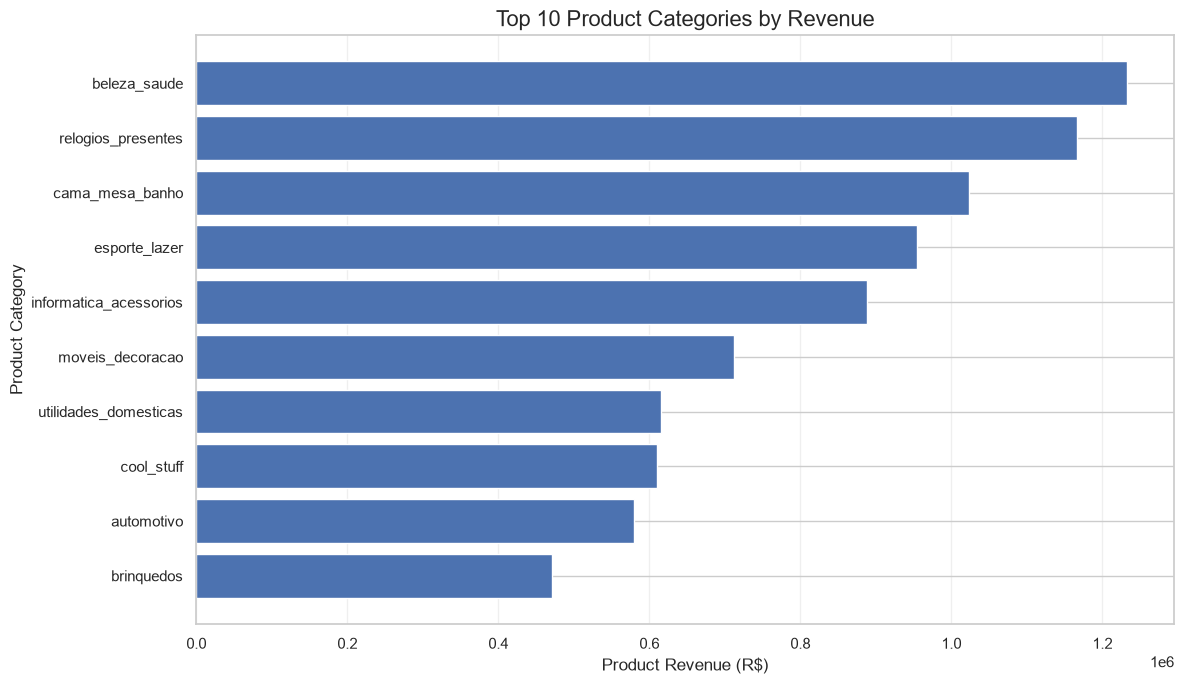

In [51]:
# %% TOP 10 PRODUCT CATEGORIES BY REVENUE

top_10_categories = category_performance.head(10).sort_values(
    "product_revenue",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["product_category_name"],
    top_10_categories["product_revenue"]
)

plt.title("Top 10 Product Categories by Revenue", fontsize=16)
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

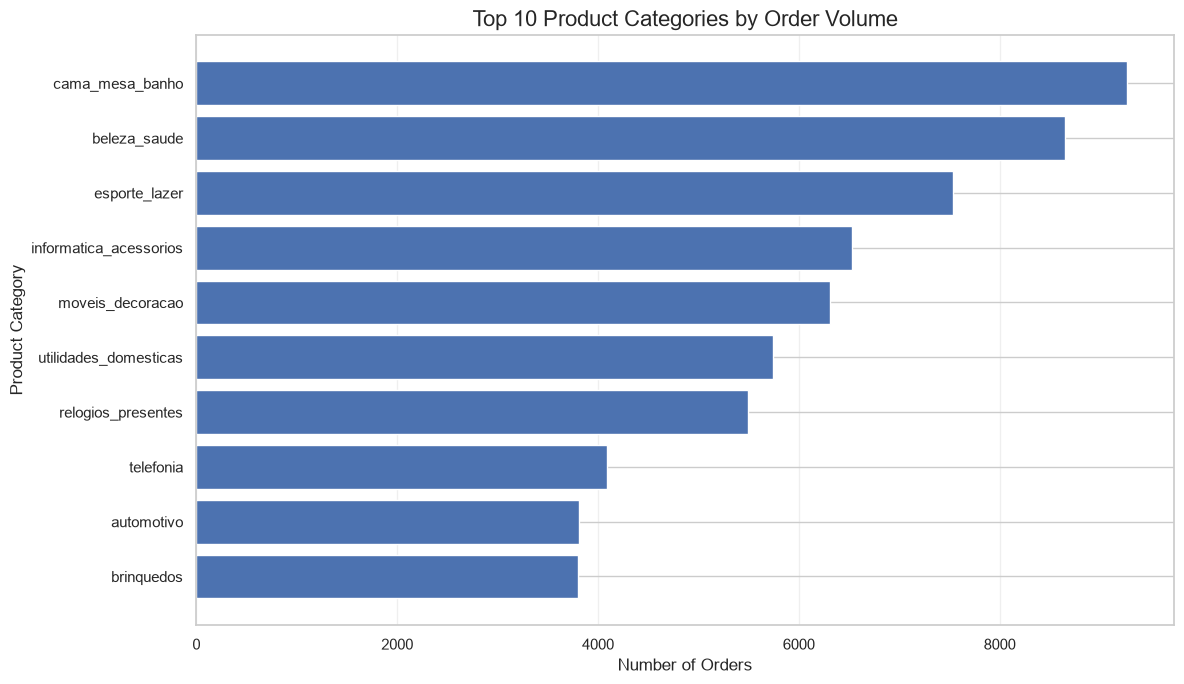

In [52]:
# %% TOP 10 CATEGORIES BY ORDER VOLUME

top_10_orders = category_performance.nlargest(
    10,
    "total_orders"
).sort_values("total_orders")

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_orders["product_category_name"],
    top_10_orders["total_orders"]
)

plt.title("Top 10 Product Categories by Order Volume", fontsize=16)
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Key finding
Beauty & Health leads revenue
R$ 1.23M

9.33% of delivered product revenue

Bed, Bath & Table leads order volume

9,272 orders

But it ranks third in product revenue.

This demonstrates why we should never evaluate product performance using revenue or volume alone.

Watches & Gifts has fewer orders but a higher average item price and category revenue per order.

Potential business interpretation: Different categories contribute to revenue through different combinations of purchase frequency and transaction value.

We should not call one category more profitable because we do not have product costs.

Unknown category item records

1,537

Out of 110,197 delivered item records - approximately 1.40%.

My earlier missing-category check returned zero because we replaced missing values with "unknown" before checking.

That's not a problem, but we should document it accurately.

Keeping the unknown category rather than deleting those records. Otherwise, we'd lose valid product revenue and order-item data.

Also, my 74 unique categories include the "unknown" bucket.

In [53]:
# %% CUSTOMER ANALYSIS DATASET

customer_orders = delivered_financial.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Customer order records:", len(customer_orders))

print(
    "Missing customer unique IDs:",
    customer_orders["customer_unique_id"].isna().sum()
)

print(
    "Unique customer IDs:",
    customer_orders["customer_id"].nunique()
)

print(
    "Unique customer identities:",
    customer_orders["customer_unique_id"].nunique()
)

display(
    customer_orders[
        [
            "order_id",
            "customer_id",
            "customer_unique_id",
            "item_revenue",
            "order_status"
        ]
    ].head()
)

Customer order records: 96478
Missing customer unique IDs: 0
Unique customer IDs: 96478
Unique customer identities: 93358


,order_id,customer_id,customer_unique_id,item_revenue,order_status
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,29.99,delivered
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,118.70,delivered
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,159.90,delivered
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,45.00,delivered
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,19.90,delivered


In [54]:
# %% CUSTOMER PURCHASE FREQUENCY

customer_frequency = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        delivered_orders=("order_id", "nunique"),
        customer_revenue=("item_revenue", "sum"),
        customer_freight=("freight_revenue", "sum")
    )
    .reset_index()
)

customer_frequency["customer_type"] = np.where(
    customer_frequency["delivered_orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

display(customer_frequency.head())

print("\n========== CUSTOMER OVERVIEW ==========")

print(
    "Unique customers:",
    customer_frequency["customer_unique_id"].nunique()
)

print(
    "One-time customers:",
    (customer_frequency["customer_type"] == "One-Time Customer").sum()
)

print(
    "Repeat customers:",
    (customer_frequency["customer_type"] == "Repeat Customer").sum()
)

,customer_unique_id,delivered_orders,customer_revenue,customer_freight,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,12.00,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,8.29,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,69.00,17.22,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,17.63,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,16.89,One-Time Customer



========== CUSTOMER OVERVIEW ==========
Unique customers: 93358
One-time customers: 90557
Repeat customers: 2801


In [55]:
# %% CUSTOMER PURCHASE FREQUENCY

customer_frequency = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        delivered_orders=("order_id", "nunique"),
        customer_revenue=("item_revenue", "sum"),
        customer_freight=("freight_revenue", "sum")
    )
    .reset_index()
)

customer_frequency["customer_type"] = np.where(
    customer_frequency["delivered_orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

display(customer_frequency.head())

print("\n========== CUSTOMER OVERVIEW ==========")

print(
    "Unique customers:",
    customer_frequency["customer_unique_id"].nunique()
)

print(
    "One-time customers:",
    (customer_frequency["customer_type"] == "One-Time Customer").sum()
)

print(
    "Repeat customers:",
    (customer_frequency["customer_type"] == "Repeat Customer").sum()
)

,customer_unique_id,delivered_orders,customer_revenue,customer_freight,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,12.00,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,8.29,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,69.00,17.22,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,17.63,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,16.89,One-Time Customer



========== CUSTOMER OVERVIEW ==========
Unique customers: 93358
One-time customers: 90557
Repeat customers: 2801


## We have now identified a major characteristic of Olist's customer behavior: most unique customers have only one delivered order in the dataset.

Let's break it down.

Unique customers

93,358
90,557

One-time customers

~97.00%
2,801

Repeat customers

~3.00%

Delivered orders

	

96,478




Unique customer identities

	

93,358




One-time customers

	

90,557




Repeat customers

	

2,801




Repeat purchase rate

	

~3.00%

## Business interpretation

The observed repeat purchase rate is approximately 3%.

This indicates that repeat delivered orders are relatively uncommon within the available dataset.

## However, we must be careful with the wording:

This is not necessarily Olist's true lifetime retention rate.

Customers may have purchased before or after the dataset's observation period.

Some customers may simply not have had enough time to make another purchase.

I call this observed repeat purchase rate among delivered customers, rather than claiming that 97% of customers were lost or churned.

## Customer Revenue Contribution

Now comes the interesting question:

Although repeat customers represent only around 3% of unique customers, how much of total revenue do they contribute?

This is a stronger business question than simply counting customers.

In [56]:
# %% CUSTOMER REVENUE SEGMENTATION

customer_segment_analysis = (
    customer_frequency
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_orders=("delivered_orders", "sum"),
        total_revenue=("customer_revenue", "sum"),
        average_customer_revenue=("customer_revenue", "mean"),
        average_orders_per_customer=("delivered_orders", "mean")
    )
    .reset_index()
)

customer_segment_analysis["customer_share_pct"] = (
    customer_segment_analysis["customers"]
    / customer_segment_analysis["customers"].sum()
) * 100

customer_segment_analysis["revenue_share_pct"] = (
    customer_segment_analysis["total_revenue"]
    / customer_segment_analysis["total_revenue"].sum()
) * 100

display(customer_segment_analysis.round(2))

,customer_type,customers,total_orders,total_revenue,average_customer_revenue,average_orders_per_customer,customer_share_pct,revenue_share_pct
0,One-Time Customer,90557,90557,12493089.36,137.96,1.00,97.0,94.49
1,Repeat Customer,2801,5921,728408.75,260.05,2.11,3.0,5.51


## This will let us compare:

Customer population share

Revenue contribution

Average revenue per customer

Average orders per customer

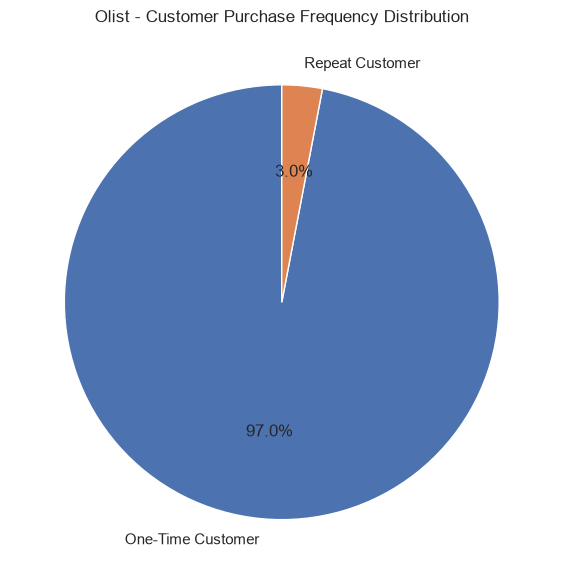

In [57]:
# %% CUSTOMER TYPE DISTRIBUTION

customer_counts = (
    customer_frequency["customer_type"]
    .value_counts()
)

plt.figure(figsize=(8, 6))

plt.pie(
    customer_counts,
    labels=customer_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Olist - Customer Purchase Frequency Distribution")

plt.tight_layout()
plt.show()

## Customer behavior: The key finding
Key business insight
3.00% of customers (Repeat customers)

5.51% of revenue (Their share of delivered product revenue)

1.89×  (Average revenue per repeat customer compared with one-time customers.)

## What this means

Insight 1 - Repeat customers generate more revenue per customer.

The average repeat customer's observed merchandise revenue is approximately 1.89 times that of a one-time customer.

Insight 2 - Revenue remains heavily dependent on one-time purchasers.

One-time customers represent 97% of the customer base and 94.49% of delivered product revenue.

Insight 3 - Repeat purchasing is relatively uncommon in the observed period.

This could be an area for further investigation around retention and customer engagement.

However, we cannot conclude that customers were lost or churned based on this dataset alone. Our analysis only captures observed delivered orders during the available period.

## How many times do customers actually purchase?

We already know that 2,801 customers made multiple delivered purchases.

Now I want to see the exact distribution:

Customers with 1 order

Customers with 2 orders

Customers with 3 orders

Customers with 4+ orders

This will help us understand whether repeat customers typically return once or whether a smaller group purchases repeatedly.

In [58]:
# %% CUSTOMER ORDER FREQUENCY DISTRIBUTION

order_frequency_distribution = (
    customer_frequency
    .groupby("delivered_orders")
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_revenue=("customer_revenue", "sum")
    )
    .reset_index()
)

order_frequency_distribution["customer_share_pct"] = (
    order_frequency_distribution["customers"]
    / order_frequency_distribution["customers"].sum()
) * 100

order_frequency_distribution["revenue_share_pct"] = (
    order_frequency_distribution["total_revenue"]
    / customer_frequency["customer_revenue"].sum()
) * 100

display(order_frequency_distribution.round(2))

,delivered_orders,customers,total_revenue,customer_share_pct,revenue_share_pct
0,1,90557,12493089.36,97.00,94.49
1,2,2573,631274.90,2.76,4.77
2,3,181,65974.42,0.19,0.50
3,4,28,18946.73,0.03,0.14
4,5,9,5616.54,0.01,0.04
5,6,5,2600.66,0.01,0.02
6,7,3,2280.02,0.00,0.02
7,9,1,1000.85,0.00,0.01
8,15,1,714.63,0.00,0.01


In [59]:
# %% CUSTOMER FREQUENCY SEGMENTS

customer_frequency["frequency_segment"] = np.select(
    [
        customer_frequency["delivered_orders"] == 1,
        customer_frequency["delivered_orders"] == 2,
        customer_frequency["delivered_orders"] == 3,
        customer_frequency["delivered_orders"] >= 4
    ],
    [
        "1 Order",
        "2 Orders",
        "3 Orders",
        "4+ Orders"
    ],
    default="Other"
)

frequency_segments = (
    customer_frequency
    .groupby("frequency_segment")
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_revenue=("customer_revenue", "sum"),
        total_orders=("delivered_orders", "sum"),
        avg_customer_revenue=("customer_revenue", "mean")
    )
    .reindex(["1 Order", "2 Orders", "3 Orders", "4+ Orders"])
    .reset_index()
)

frequency_segments["customer_share_pct"] = (
    frequency_segments["customers"]
    / frequency_segments["customers"].sum()
) * 100

frequency_segments["revenue_share_pct"] = (
    frequency_segments["total_revenue"]
    / frequency_segments["total_revenue"].sum()
) * 100

display(frequency_segments.round(2))

,frequency_segment,customers,total_revenue,total_orders,avg_customer_revenue,customer_share_pct,revenue_share_pct
0,1 Order,90557,12493089.36,90557,137.96,97.00,94.49
1,2 Orders,2573,631274.90,5146,245.35,2.76,4.77
2,3 Orders,181,65974.42,543,364.50,0.19,0.50
3,4+ Orders,47,31159.43,232,662.97,0.05,0.24


## The more frequently customers purchase, the higher their observed average revenue per customer becomes.

Customer behavior insight

90,557 customers purchased exactly once - 97.00% of the customer base.

Finding 1 - The customer base is predominantly one-time purchasers.

97% of customers made exactly one delivered purchase during the observed period.

Finding 2 - Higher-frequency segments have higher average customer revenue.

The 4+ order segment has approximately 4.81 times the average revenue per customer of the one-order segment.

Finding 3 - The highest-frequency segment is very small.

Only 47 customers made at least four delivered purchases. This segment accounts for 0.24% of revenue, so its average should be interpreted with the small sample size in mind.

These are associations, not proof that increasing purchase frequency alone causes higher customer revenue.

the following chart will be more useful than another pie chart because it shows the difference in customer counts across purchase frequencies.

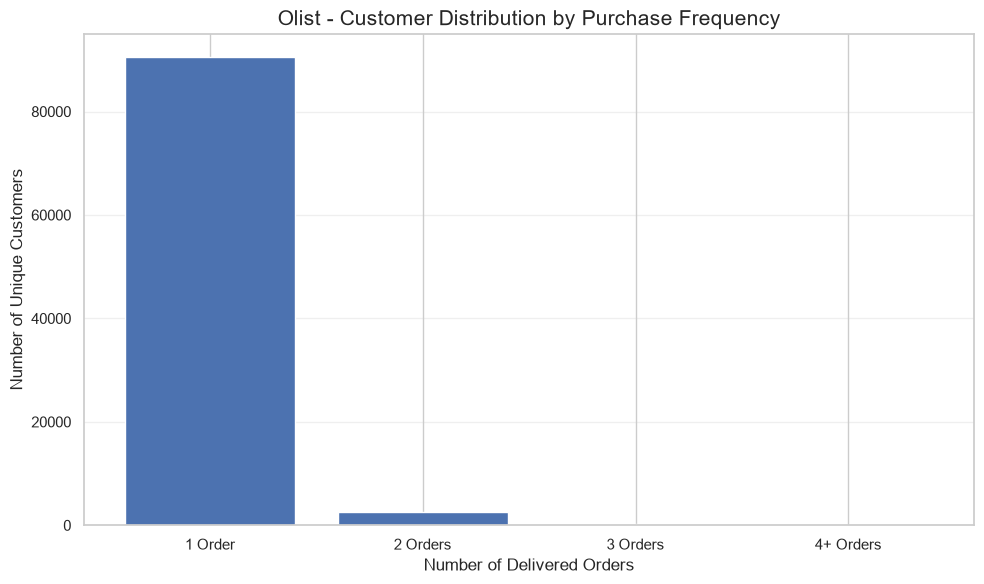

In [60]:
# %% CUSTOMER ORDER FREQUENCY DISTRIBUTION

plt.figure(figsize=(10, 6))

plt.bar(
    frequency_segments["frequency_segment"],
    frequency_segments["customers"]
)

plt.title(
    "Olist - Customer Distribution by Purchase Frequency",
    fontsize=15
)

plt.xlabel("Number of Delivered Orders")
plt.ylabel("Number of Unique Customers")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Customer Lifetime Value (Observed)

Now I want to go beyond frequency.

I'll investigate:

Top 10 customers by delivered product revenue.

Average customer revenue.

Median customer revenue.

Revenue concentration among the highest-spending customers.

One important distinction: because the dataset does not provide complete customer lifetime histories, we'll call this observed customer revenue, not predictive lifetime value.

In [61]:
# %% CUSTOMER REVENUE DISTRIBUTION

print("========== CUSTOMER REVENUE STATISTICS ==========")

print(
    customer_frequency["customer_revenue"].describe().round(2)
)

print("\n========== TOP 10 CUSTOMERS BY REVENUE ==========")

top_customers = customer_frequency.sort_values(
    "customer_revenue",
    ascending=False
).head(10)

display(top_customers.round(2))

========== CUSTOMER REVENUE STATISTICS ==========
count    93358.00
mean       141.62
std        215.69
min          0.85
25%         47.65
50%         89.73
75%        154.74
max      13440.00
Name: customer_revenue, dtype: float64

========== TOP 10 CUSTOMERS BY REVENUE ==========


,customer_unique_id,delivered_orders,customer_revenue,customer_freight,customer_type,frequency_segment
3724,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,224.08,One-Time Customer,1 Order
79636,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,183.63,Repeat Customer,2 Orders
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,114.88,One-Time Customer,1 Order
80463,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,194.31,One-Time Customer,1 Order
25436,459bef486812aa25204be022145caa62,1,6729.0,193.21,One-Time Customer,1 Order
93081,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0,227.66,One-Time Customer,1 Order
23411,4007669dec559734d6f53e029e360987,1,5934.6,146.94,One-Time Customer,1 Order
87148,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0,74.34,One-Time Customer,1 Order
26640,48e1ac109decbb87765a3eade6854098,1,4590.0,91.78,One-Time Customer,1 Order
59163,a229eba70ec1c2abef51f04987deb7a5,1,4400.0,45.50,One-Time Customer,1 Order


The mean is approximately 58% higher than the median.

This indicates that a relatively small number of high-spending customers pull the average upward.

For business reporting, we should present both mean and median instead of relying on the average alone.

## The highest-spending customer purchased only once

The highest observed customer revenue is R$13,440 from one delivered order.

This is a valuable analytical distinction:

High customer revenue does not necessarily mean repeat purchasing.

A single large basket can generate more revenue than multiple smaller orders.

We should investigate the order's item composition before calling it an outlier or data error.

The customer IDs are anonymized, so we'll use them for internal analysis without treating them as personally identifying information.

## Next: Customer Revenue Concentration

Let's answer an important business question:

What proportion of total customer revenue is generated by the top 1% and top 10% of customers?

This will help us understand revenue concentration.

In [62]:
# %% CUSTOMER REVENUE CONCENTRATION

customer_revenue_sorted = customer_frequency.sort_values(
    "customer_revenue",
    ascending=False
).reset_index(drop=True)

total_customer_revenue = customer_revenue_sorted[
    "customer_revenue"
].sum()

top_1_count = int(np.ceil(len(customer_revenue_sorted) * 0.01))
top_10_count = int(np.ceil(len(customer_revenue_sorted) * 0.10))

top_1_revenue = customer_revenue_sorted.head(
    top_1_count
)["customer_revenue"].sum()

top_10_revenue = customer_revenue_sorted.head(
    top_10_count
)["customer_revenue"].sum()

print("========== CUSTOMER REVENUE CONCENTRATION ==========")

print(f"Total Customers: {len(customer_revenue_sorted):,}")

print(f"Top 1% Customers: {top_1_count:,}")
print(f"Top 1% Revenue Share: {top_1_revenue / total_customer_revenue * 100:.2f}%")

print(f"Top 10% Customers: {top_10_count:,}")
print(f"Top 10% Revenue Share: {top_10_revenue / total_customer_revenue * 100:.2f}%")

========== CUSTOMER REVENUE CONCENTRATION ==========
Total Customers: 93,358
Top 1% Customers: 934
Top 1% Revenue Share: 11.47%
Top 10% Customers: 9,336
Top 10% Revenue Share: 41.10%


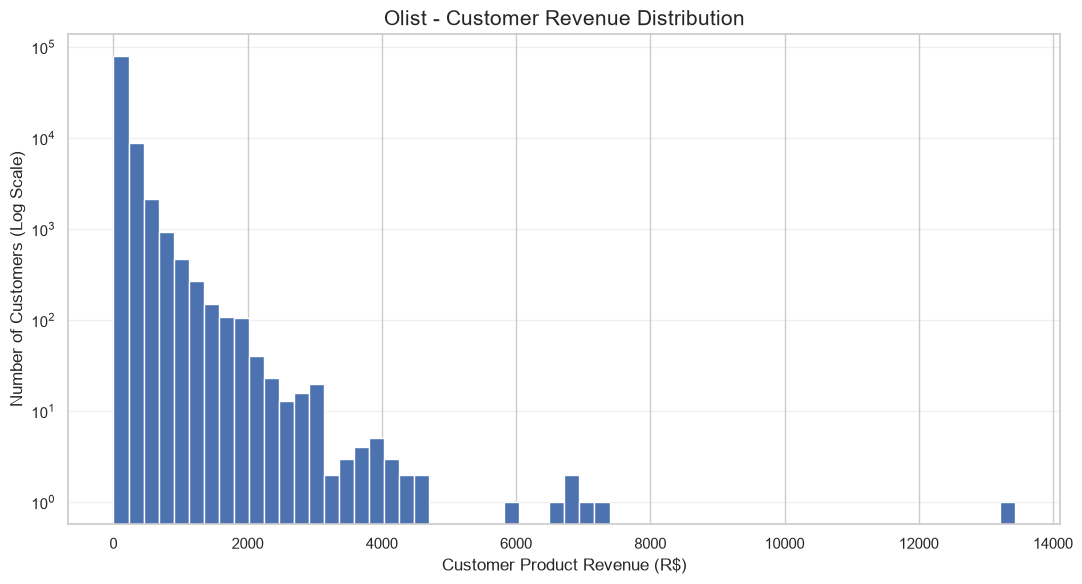

In [63]:
# %% CUSTOMER REVENUE DISTRIBUTION

plt.figure(figsize=(11, 6))

plt.hist(
    customer_frequency["customer_revenue"],
    bins=60,
    log=True
)

plt.title("Olist - Customer Revenue Distribution", fontsize=15)
plt.xlabel("Customer Product Revenue (R$)")
plt.ylabel("Number of Customers (Log Scale)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Customer revenue distribution confirms that Olist's customer spending is heavily right-skewed, and the concentration analysis quantifies exactly how much revenue comes from the highest-spending customers.

41.10% Of delivered product revenue comes from the top 10% of customers.

11.47% Revenue from top 1%

58.90% Revenue from remaining 90%

The logarithmic vertical axis makes it easier to see the distribution when some revenue ranges contain vastly more customers than others.

Chart shows:

A large concentration of customers at relatively low revenue values.

A declining number of customers as revenue increases.

A long right tail containing a small number of high-spending customers.

A few exceptionally high observations, including the R$13,440 customer.

This supports our earlier finding that the mean customer revenue (R$141.62) is higher than the median (R$89.73).

Business interpretation

The top 10% of customers contribute 41.10% of observed merchandise revenue, while representing only 10% of the customer base.

This is useful for customer segmentation and further investigation of high-value customer behavior.

It does not, by itself, establish that the business depends on those customers or that they will continue purchasing.

A Pareto chart will show cumulative revenue contribution as we move from the highest-spending customers to the rest.

This is more informative than the histogram for understanding revenue concentration.

In [64]:
# %% CUSTOMER REVENUE PARETO ANALYSIS

customer_pareto = customer_frequency.sort_values(
    "customer_revenue",
    ascending=False
).reset_index(drop=True)

customer_pareto["customer_rank_pct"] = (
    (customer_pareto.index + 1)
    / len(customer_pareto)
) * 100

customer_pareto["cumulative_revenue"] = (
    customer_pareto["customer_revenue"].cumsum()
)

customer_pareto["cumulative_revenue_pct"] = (
    customer_pareto["cumulative_revenue"]
    / customer_pareto["customer_revenue"].sum()
) * 100

display(customer_pareto.head(10))

,customer_unique_id,delivered_orders,customer_revenue,customer_freight,customer_type,frequency_segment,customer_rank_pct,cumulative_revenue,cumulative_revenue_pct
0,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,224.08,One-Time Customer,1 Order,0.001071,13440.0,0.101653
1,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,183.63,Repeat Customer,2 Orders,0.002142,20828.0,0.157531
2,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,114.88,One-Time Customer,1 Order,0.003213,27988.0,0.211686
3,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,194.31,One-Time Customer,1 Order,0.004285,34723.0,0.262625
4,459bef486812aa25204be022145caa62,1,6729.0,193.21,One-Time Customer,1 Order,0.005356,41452.0,0.313520
5,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0,227.66,One-Time Customer,1 Order,0.006427,47951.0,0.362674
6,4007669dec559734d6f53e029e360987,1,5934.6,146.94,One-Time Customer,1 Order,0.007498,53885.6,0.407560
7,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0,74.34,One-Time Customer,1 Order,0.008569,58575.6,0.443033
8,48e1ac109decbb87765a3eade6854098,1,4590.0,91.78,One-Time Customer,1 Order,0.009640,63165.6,0.477749
9,a229eba70ec1c2abef51f04987deb7a5,1,4400.0,45.50,One-Time Customer,1 Order,0.010711,67565.6,0.511028


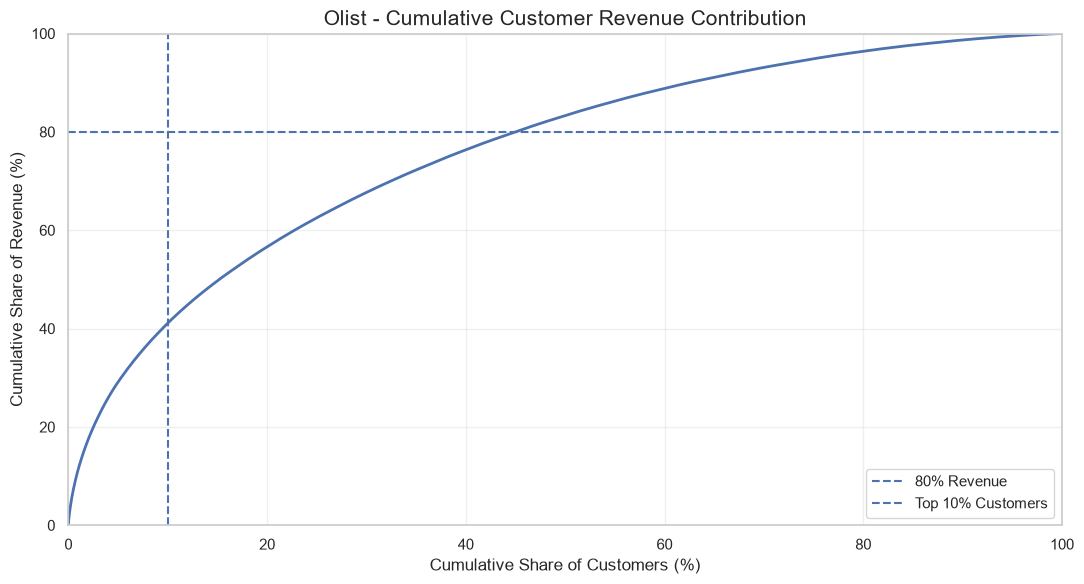

In [65]:
# %% CUSTOMER REVENUE CONCENTRATION CURVE

plt.figure(figsize=(11, 6))

plt.plot(
    customer_pareto["customer_rank_pct"],
    customer_pareto["cumulative_revenue_pct"],
    linewidth=2
)

plt.axhline(
    80,
    linestyle="--",
    label="80% Revenue"
)

plt.axvline(
    10,
    linestyle="--",
    label="Top 10% Customers"
)

plt.title(
    "Olist - Cumulative Customer Revenue Contribution",
    fontsize=15
)

plt.xlabel("Cumulative Share of Customers (%)")
plt.ylabel("Cumulative Share of Revenue (%)")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Revenue concentration

41.10% Revenue contributed by the top 10% of customers.

~44% Approximate share of customers needed to generate 80% of revenue, visually estimated from the curve.

Customer revenue exhibits a right-skewed distribution, with the top 10% of customers contributing 41.10% of delivered product revenue. This highlights differences in customer value and provides a basis for further customer segmentation.

## Next chapter: Geographic Performance 🇧🇷

In [66]:
# %% CUSTOMER LOCATION DATA QUALITY

print("Customer columns:")
print(customers.columns.tolist())

print("\nCustomer dataset shape:")
print(customers.shape)

print("\nMissing customer states:")
print(customers["customer_state"].isna().sum())

print("\nUnique states:")
print(customers["customer_state"].nunique())

print("\nOrders by customer state:")
display(
    customers["customer_state"].value_counts().to_frame("customer_records")
)

Customer columns:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Customer dataset shape:
(99441, 5)

Missing customer states:
0

Unique states:
27

Orders by customer state:


,customer_records
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


In [67]:
# %% GEOGRAPHIC ANALYSIS DATASET

geo_orders = delivered_financial.merge(
    customers[
        ["customer_id", "customer_unique_id", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Geographic order records:", len(geo_orders))
print("Missing states:", geo_orders["customer_state"].isna().sum())

display(
    geo_orders[
        [
            "order_id",
            "customer_unique_id",
            "customer_state",
            "item_revenue",
            "freight_revenue"
        ]
    ].head()
)

Geographic order records: 96478
Missing states: 0


,order_id,customer_unique_id,customer_state,item_revenue,freight_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,RN,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,SP,19.90,8.72


In [68]:
# %% STATE PERFORMANCE ANALYSIS

state_performance = (
    geo_orders
    .groupby("customer_state")
    .agg(
        delivered_orders=("order_id", "nunique"),
        unique_customers=("customer_unique_id", "nunique"),
        product_revenue=("item_revenue", "sum"),
        freight_revenue=("freight_revenue", "sum")
    )
    .reset_index()
)

state_performance["product_aov"] = (
    state_performance["product_revenue"]
    / state_performance["delivered_orders"]
)

state_performance["revenue_share_pct"] = (
    state_performance["product_revenue"]
    / state_performance["product_revenue"].sum()
) * 100

state_performance = state_performance.sort_values(
    "product_revenue",
    ascending=False
)

display(state_performance.round(2))

,customer_state,delivered_orders,unique_customers,product_revenue,freight_revenue,product_aov,revenue_share_pct
25,SP,40501,39156,5067633.16,702069.99,125.12,38.33
18,RJ,12350,11917,1759651.13,295750.44,142.48,13.31
10,MG,11354,11001,1552481.83,266409.84,136.73,11.74
22,RS,5345,5168,728897.47,132575.32,136.37,5.51
17,PR,4923,4769,666063.51,115645.29,135.30,5.04
23,SC,3546,3449,507012.13,88115.65,142.98,3.83
4,BA,3256,3158,493584.14,97553.67,151.59,3.73
6,DF,2080,2019,296498.41,49624.94,142.55,2.24
8,GO,1957,1895,282836.70,51375.65,144.53,2.14
7,ES,1995,1928,268643.45,49014.48,134.66,2.03


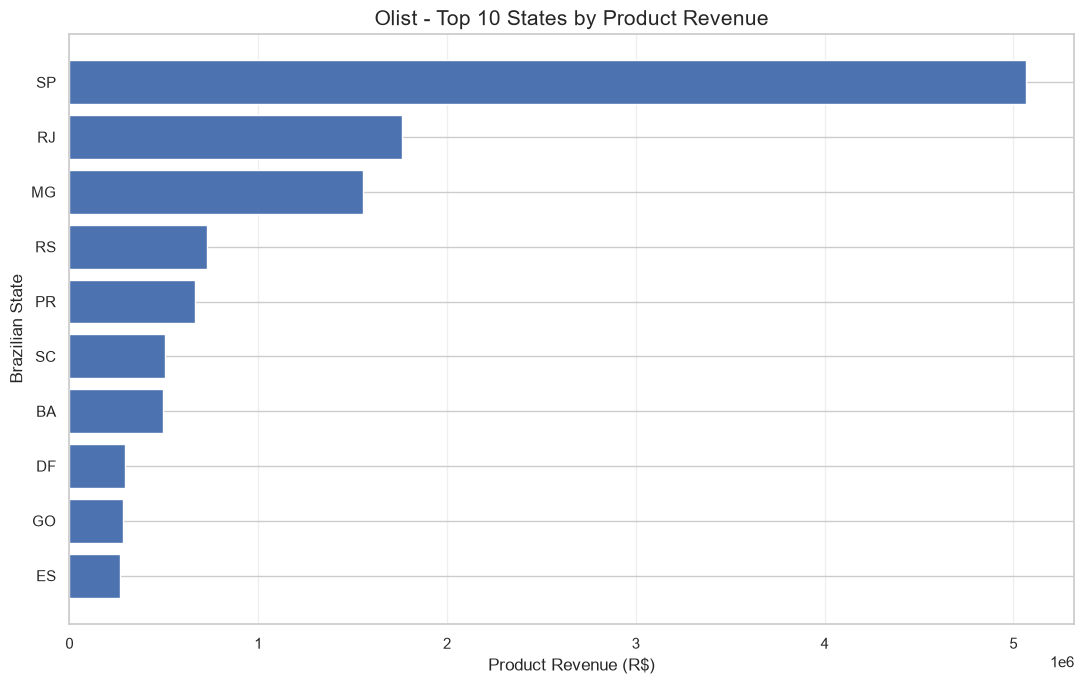

In [69]:
# %% TOP 10 STATES BY REVENUE

top_states = state_performance.head(10).sort_values(
    "product_revenue",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_states["customer_state"],
    top_states["product_revenue"]
)

plt.title("Olist - Top 10 States by Product Revenue", fontsize=15)
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Brazilian State")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Major finding

São Paulo (SP) product revenue R$5.07 million, 38.33% of total product revenue.

Top 3 states - SP, RJ, MG 63.38% Combined share of delivered product revenue.

## What we can conclude
Finding 1 - Revenue is geographically concentrated

SP alone contributes 38.33% of delivered product revenue. SP, RJ, and MG together contribute 63.38%.

This is a descriptive concentration finding, not proof of why those states generate more revenue.

Finding 2 - Revenue leadership and AOV leadership are different

SP leads in total revenue, but its product AOV is R$125.12.

For comparison:

BA: R$151.59

SC: R$142.98

RJ: R$142.48

PB: R$217.77, based on only 517 delivered orders

This demonstrates why we should examine order volume and average order value together. AOVs from states with relatively few orders should be interpreted cautiously.

Finding 3 - Customer records and delivered customers are different populations

Original customer table contains 99,441 customer-order records, while your geographic delivered-order analysis contains 96,478 delivered orders.

That's expected because the geographic KPI table uses delivered orders only.

## Next: Geographic Delivery Performance

Now we connect commercial performance to operations.

Our next question:

Are some states experiencing longer delivery times or higher late-delivery rates than others?

This adds an operational dimension to your project rather than limiting it to sales.

In [70]:
# %% GEOGRAPHIC DELIVERY PERFORMANCE

state_delivery = (
    geo_orders
    .groupby("customer_state")
    .agg(
        delivered_orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median"),
        late_orders=("delivery_performance", lambda x: (x == "Late").sum()),
        early_orders=("delivery_performance", lambda x: (x == "Early").sum()),
        unknown_delivery=("delivery_days", lambda x: x.isna().sum())
    )
    .reset_index()
)

state_delivery["late_rate_pct"] = (
    state_delivery["late_orders"]
    / (
        state_delivery["delivered_orders"]
        - state_delivery["unknown_delivery"]
    )
) * 100

state_delivery = state_delivery.sort_values(
    "delivered_orders",
    ascending=False
)

display(state_delivery.round(2))

,customer_state,delivered_orders,avg_delivery_days,median_delivery_days,late_orders,early_orders,unknown_delivery,late_rate_pct
25,SP,40501,8.76,7.21,2387,38107,7,5.89
18,RJ,12350,15.31,12.04,1664,10686,0,13.47
10,MG,11354,12.01,10.31,637,10717,0,5.61
22,RS,5345,15.30,13.18,382,4962,1,7.15
17,PR,4923,11.99,10.43,246,4677,0,5.00
23,SC,3546,14.95,13.01,346,3200,0,9.76
4,BA,3256,19.34,16.91,457,2799,0,14.04
6,DF,2080,12.97,11.36,147,1933,0,7.07
7,ES,1995,15.79,13.64,244,1751,0,12.23
8,GO,1957,15.61,13.95,160,1797,0,8.18


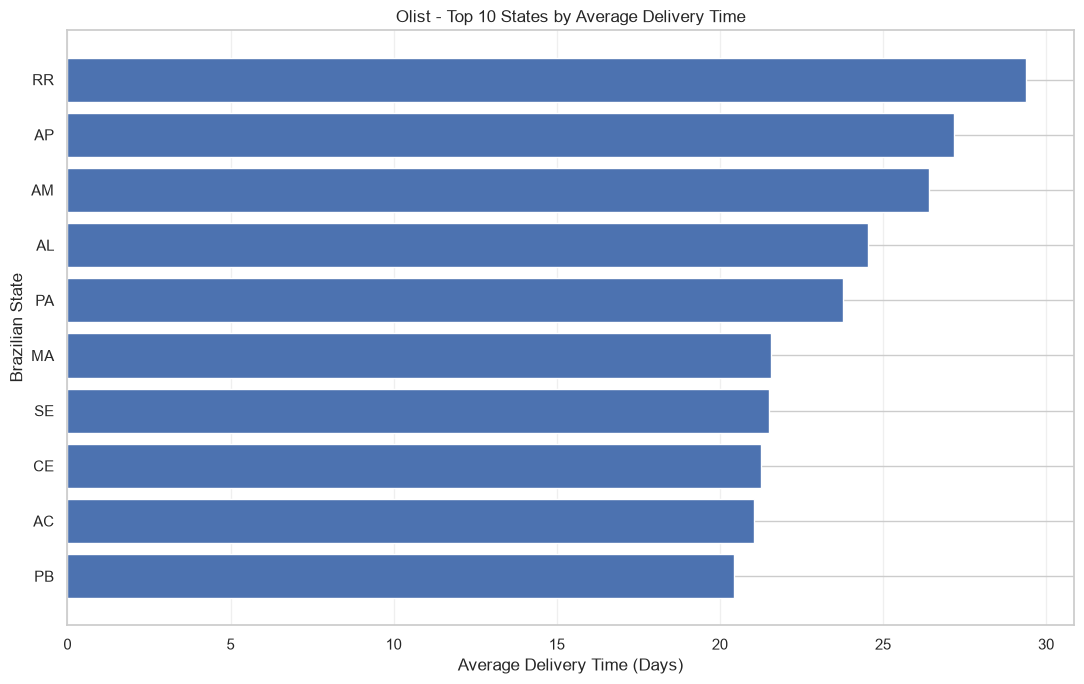

In [71]:
# %% TOP 10 STATES BY AVERAGE DELIVERY TIME

slowest_states = (
    state_delivery
    .dropna(subset=["avg_delivery_days"])
    .sort_values("avg_delivery_days", ascending=False)
    .head(10)
    .sort_values("avg_delivery_days")
)

plt.figure(figsize=(11, 7))

plt.barh(
    slowest_states["customer_state"],
    slowest_states["avg_delivery_days"]
)

plt.title("Olist - Top 10 States by Average Delivery Time")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("Brazilian State")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

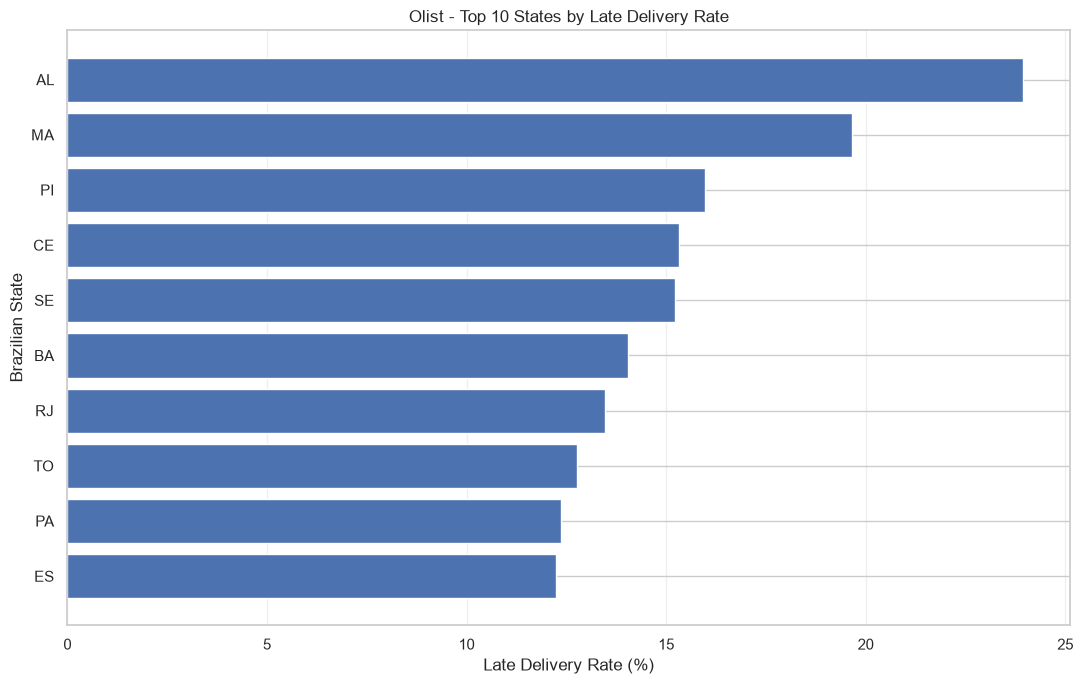

In [72]:
# %% LATE DELIVERY RATE BY STATE

late_states = (
    state_delivery
    .dropna(subset=["late_rate_pct"])
    .sort_values("late_rate_pct", ascending=False)
    .head(10)
    .sort_values("late_rate_pct")
)

plt.figure(figsize=(11, 7))

plt.barh(
    late_states["customer_state"],
    late_states["late_rate_pct"]
)

plt.title("Olist - Top 10 States by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Brazilian State")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The late rate denominator excludes orders with missing delivery duration. This prevents unknown delivery outcomes from being counted as on-time or late.

We now have two separate geographic dimensions:

Delivery speed: How long customers waited.

Late delivery rate: How frequently orders missed the estimated delivery date.

And they reveal something important: the state with the longest average delivery time is not necessarily the state with the highest late-delivery rate.

## Key operational finding

SP - 40,501 delivered orders 8.76 days of Average delivery time and 5.89% late rate

AL - 397 delivered orders 23.93% Late delivery rate, the highest among the 27 states in the table.

Finding 1 — Delivery time and lateness are not the same metric

RR has the longest average delivery time at 29.39 days, but its late rate is 12.20%.

AL has a shorter average delivery time of 24.54 days, but a higher late rate of 23.93%.

This distinction matters because an order can take a long time to arrive while still meeting its estimated delivery date.

Finding 2 - SP has a different operating profile

SP accounts for 40,501 delivered orders, with an average delivery time of 8.76 days and a late rate of 5.89%.

Its large order volume makes it particularly useful as a benchmark for further state-level comparisons.

Finding 3 - Sample sizes matter

RR has only 41 delivered orders, compared with 40,501 in SP.

We should avoid interpreting small-state percentages as stable estimates of long-term performance.

## Next chapter: Customer Satisfaction & Reviews

Now we're going to connect three datasets:

Orders

Delivery performance

Customer reviews

Our central question:

Are late deliveries associated with lower customer review scores?

This is an association analysis, not proof that delivery delays caused a lower rating.

In [73]:
# %% CUSTOMER REVIEW DATA QUALITY

print("Review dataset shape:", order_reviews.shape)

print("\nReview columns:")
print(order_reviews.columns.tolist())

print("\nReview score distribution:")
display(
    order_reviews["review_score"]
    .value_counts()
    .sort_index()
    .to_frame("review_count")
)

print("\nMissing review scores:")
print(order_reviews["review_score"].isna().sum())

print("\nDuplicate review order IDs:")
print(order_reviews["order_id"].duplicated().sum())

Review dataset shape: (99224, 7)

Review columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Review score distribution:


,review_count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328



Missing review scores:
0

Duplicate review order IDs:
551


## Step 2 - Prepare one review record per order

We need to avoid multiplying order revenue or delivery records if an order has multiple review entries.

We'll aggregate reviews to the order level.

In [74]:
# %% AGGREGATE REVIEWS BY ORDER

reviews_by_order = (
    order_reviews
    .groupby("order_id")
    .agg(
        review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

print("Unique reviewed orders:", reviews_by_order["order_id"].nunique())

display(reviews_by_order.head())

Unique reviewed orders: 98673


,order_id,review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,4.0,1
2,000229ec398224ef6ca0657da4fc703e,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1


In [75]:
# %% DELIVERY AND REVIEW ANALYSIS DATASET

delivery_reviews = geo_orders.merge(
    reviews_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Delivered orders:", len(delivery_reviews))
print("Missing review scores:", delivery_reviews["review_score"].isna().sum())

display(
    delivery_reviews[
        [
            "order_id",
            "customer_state",
            "delivery_days",
            "delivery_performance",
            "review_score"
        ]
    ].head()
)

Delivered orders: 96478
Missing review scores: 646


,order_id,customer_state,delivery_days,delivery_performance,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,8.436574,Early,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,13.782037,Early,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,9.394213,Early,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,13.208750,Early,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,2.873877,Early,5.0


In [76]:
# %% REVIEW SCORE BY DELIVERY PERFORMANCE

delivery_review_summary = (
    delivery_reviews
    .dropna(subset=["review_score"])
    .groupby("delivery_performance")
    .agg(
        orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median")
    )
    .reset_index()
)

display(delivery_review_summary.round(2))

,delivery_performance,orders,average_review_score,median_review_score
0,Early,88163,4.29,5.0
1,Late,7661,2.57,2.0
2,Unknown,8,4.50,5.0


We have a substantial difference in customer satisfaction between orders delivered early and orders delivered late.

## Major business finding

Average review score - Early deliveries 4.29 / 5

Average review score - Late deliveries 2.57 / 5

1.72 points Difference in average review scores.

## What stands out?

1. Late deliveries are associated with substantially lower customer ratings.

The average review score for late orders is 1.72 points below that of early orders.

2. The median tells an even clearer story.

Early: 5 stars

Late: 2 stars

Half of the reviewed early-delivery orders have scores at or above 5, while half of the late-delivery orders have scores at or below 2.

3. We have enough observations to investigate this relationship further.

There are 7,661 reviewed late orders, compared with 88,163 reviewed early orders.

This is a descriptive association. We cannot conclude from this comparison alone that late delivery caused the lower scores; other factors may contribute.

## Let's quantify negative reviews

For our business analysis, let's define:

Low rating: 1-2 stars

Neutral rating: 3 stars

High rating: 4-5 stars

We'll calculate the percentage of each group by delivery performance.

In [77]:
# %% REVIEW RATING DISTRIBUTION BY DELIVERY PERFORMANCE

review_analysis = delivery_reviews.dropna(
    subset=["review_score"]
).copy()

review_analysis["rating_group"] = np.select(
    [
        review_analysis["review_score"] <= 2,
        review_analysis["review_score"] == 3,
        review_analysis["review_score"] >= 4
    ],
    [
        "Low Rating (1-2)",
        "Neutral (3)",
        "High Rating (4-5)"
    ],
    default="Other"
)

rating_distribution = pd.crosstab(
    review_analysis["delivery_performance"],
    review_analysis["rating_group"],
    normalize="index"
) * 100

display(rating_distribution.round(2))

rating_group,High Rating (4-5),Low Rating (1-2),Neutral (3),Other
delivery_performance,,,,
Early,82.77,9.19,7.99,0.05
Late,34.56,53.99,11.33,0.12
Unknown,87.50,12.50,0.00,0.00


In [78]:
# %% STAR RATING DISTRIBUTION

star_distribution = pd.crosstab(
    review_analysis["delivery_performance"],
    review_analysis["review_score"],
    normalize="index"
) * 100

display(star_distribution.round(2))

review_score,1.000000,1.500000,2.000000,2.500000,3.000000,3.333333,3.500000,4.000000,4.333333,4.500000,5.000000
delivery_performance,,,,,,,,,,,
Early,6.55,0.01,2.62,0.03,7.99,0.0,0.02,20.33,0.0,0.06,62.38
Late,46.12,0.01,7.86,0.08,11.33,0.0,0.04,12.34,0.0,0.03,22.20
Unknown,12.50,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.00,87.50


This will show us whether the difference is mainly driven by 1-star reviews, 2-star reviews, or a broader shift across the rating scale.

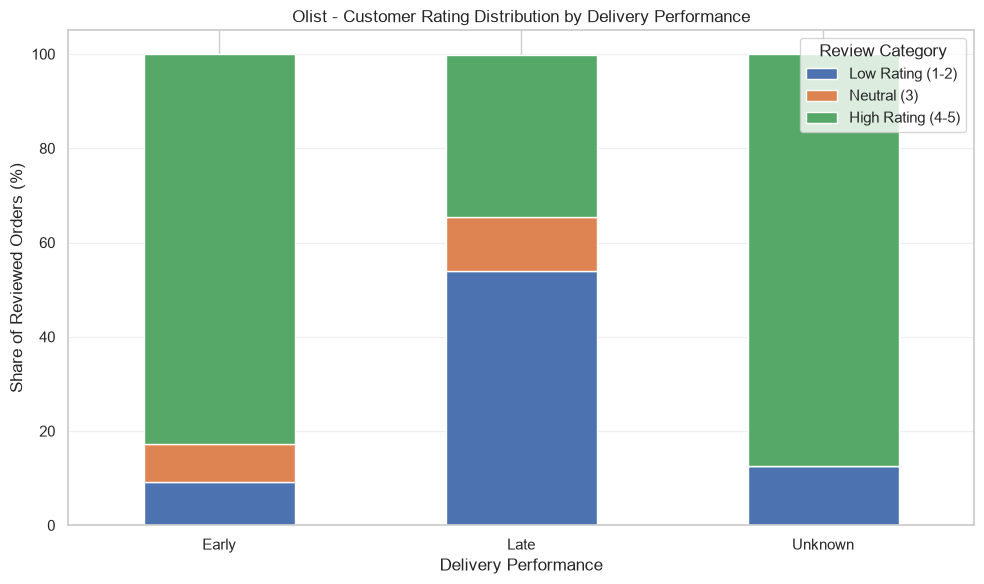

In [79]:
# %% CUSTOMER SATISFACTION BY DELIVERY PERFORMANCE

rating_plot = rating_distribution.loc[
    ["Early", "Late", "Unknown"],
    ["Low Rating (1-2)", "Neutral (3)", "High Rating (4-5)"]
]

rating_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title(
    "Olist - Customer Rating Distribution by Delivery Performance"
)

plt.xlabel("Delivery Performance")
plt.ylabel("Share of Reviewed Orders (%)")

plt.xticks(rotation=0)
plt.legend(title="Review Category")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Key findings

1. Late deliveries are associated with substantially lower customer satisfaction.

The average rating differs by 1.72 points between early and late deliveries.

2. More than half of reviewed late orders received a rating of 1 or 2.

Late deliveries: 53.99% low ratings.

Early deliveries: 9.19% low ratings.

3. Early deliveries have a much larger share of positive ratings.

82.77% of early-delivery reviews were 4 or 5, compared with 34.56% for late deliveries.

4. Unknown delivery performance has only 8 reviewed orders.

Don't draw conclusions from that group yet, the sample is too small.

Delivery performance is strongly associated with customer satisfaction in the analyzed Olist dataset. Late deliveries are associated with a substantially higher proportion of negative reviews, suggesting that delivery reliability is an important operational factor to investigate when improving customer experience.

Important: this is an association, not proof that delivery delays alone caused the lower ratings.

## Next step: quantify the relationship between delivery delay and customer ratings

We have compared Early vs Late. Now let's investigate whether the rating changes as the number of days late increases.

We'll group orders into delivery-delay ranges and calculate their average rating.

This can help answer a more specific business question:

Does customer satisfaction deteriorate as delivery delays become longer?

In [80]:

# Prepare review and delivery data for analysis

review_delivery = order_reviews.merge(
    orders[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
        ]
    ],
    on="order_id",
    how="inner",
)

# Calculate actual delivery duration in days
review_delivery["delivery_days"] = (
    review_delivery["order_delivered_customer_date"]
    - review_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("Review-delivery dataset shape:", review_delivery.shape)
display(review_delivery.head())


Review-delivery dataset shape: (99224, 11)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,No comment,No comment,2018-01-18 00:00:00,2018-01-18 21:46:59,2018-01-11 15:30:49,2018-01-17 18:42:41,2018-02-02,6.133241
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,No comment,No comment,2018-03-10 00:00:00,2018-03-11 03:05:13,2018-02-28 12:25:19,2018-03-09 23:17:20,2018-03-14,9.452789
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,No comment,No comment,2018-02-17 00:00:00,2018-02-18 14:36:24,2018-02-03 09:56:22,2018-02-16 17:28:48,2018-03-09,13.314190
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,No comment,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,2017-04-09 17:41:13,2017-04-20 09:08:35,2017-05-10,10.644005
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,No comment,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,2018-02-10 10:59:03,2018-02-28 16:33:35,2018-03-09,18.232315


In [81]:
# %% DELIVERY DELAY VS CUSTOMER SATISFACTION

delay_analysis = review_delivery[
    review_delivery["review_score"].notna() &
    review_delivery["delivery_days"].notna()
].copy()

# Calculate delivery delay relative to estimated delivery date
delay_analysis["delay_days"] = (
    delay_analysis["order_delivered_customer_date"] -
    delay_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Create delay categories
delay_analysis["delay_group"] = pd.cut(
    delay_analysis["delay_days"],
    bins=[-float("inf"), 0, 3, 7, 14, float("inf")],
    labels=[
        "On Time / Early",
        "1-3 Days Late",
        "4-7 Days Late",
        "8-14 Days Late",
        "15+ Days Late"
    ]
)

delay_summary = (
    delay_analysis.groupby("delay_group", observed=False)
    .agg(
        orders=("order_id", "nunique"),
        average_rating=("review_score", "mean"),
        median_rating=("review_score", "median"),
        low_rating_count=("review_score", lambda x: x.isin([1, 2]).sum()),
        high_rating_count=("review_score", lambda x: x.isin([4, 5]).sum())
    )
    .reset_index()
)

delay_summary["low_rating_pct"] = (
    delay_summary["low_rating_count"] /
    delay_summary["orders"] * 100
).round(2)

delay_summary["high_rating_pct"] = (
    delay_summary["high_rating_count"] /
    delay_summary["orders"] * 100
).round(2)

delay_summary["average_rating"] = delay_summary["average_rating"].round(2)

display(delay_summary)

,delay_group,orders,average_rating,median_rating,low_rating_count,high_rating_count,low_rating_pct,high_rating_pct
0,On Time / Early,88168,4.29,5.0,8190,73382,9.29,83.23
1,1-3 Days Late,2636,3.77,4.0,507,1759,19.23,66.73
2,4-7 Days Late,1773,2.32,1.0,1090,495,61.48,27.92
3,8-14 Days Late,1749,1.75,1.0,1371,225,78.39,12.86
4,15+ Days Late,1504,1.71,1.0,1192,186,79.26,12.37


In [82]:
# %% FIND EXISTING DATAFRAMES

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

customers: (99441, 5)
geolocation: (1000163, 5)
order_items: (112650, 7)
order_payments: (103886, 5)
order_reviews: (99224, 7)
orders: (99441, 12)
products: (32951, 10)
sellers: (3095, 4)
category_translation: (71, 2)
df: (32951, 10)
summary: (0, 2)
missing_delivered: (8, 12)
items_agg: (98666, 4)
payments_agg: (99440, 3)
financial_orders: (99441, 19)
missing_items: (775, 18)
missing_payments: (1, 18)
reconciliation: (98665, 20)
higher_orders: (291, 20)
higher_payment_details: (310, 5)
lower_orders: (90, 20)
missing_item_orders: (775, 19)
matched_financial: (98665, 19)
delivered_financial: (96478, 20)
monthly_revenue: (24, 7)
top_revenue_months: (10, 7)
delivered_items: (110197, 7)
category_items: (110197, 8)
category_performance: (74, 8)
top_10_categories: (10, 8)
top_10_orders: (10, 8)
customer_orders: (96478, 21)
customer_frequency: (93358, 6)
customer_segment_analysis: (2, 8)
order_frequency_distribution: (9, 5)
frequency_segments: (4, 7)
top_customers: (10, 6)
customer_revenue_sor

In [83]:
# %% INSPECT REVIEW ANALYSIS

print("Columns:")
print(review_analysis.columns.tolist())

print("\nSample:")
display(review_analysis.head())

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_status', 'delivery_days', 'delivery_delay_days', 'delivery_performance', 'total_items', 'item_revenue', 'freight_revenue', 'payment_total', 'payment_records', 'order_total', 'payment_difference', 'purchase_month', 'customer_unique_id', 'customer_state', 'review_score', 'review_count', 'rating_group']

Sample:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_status,delivery_days,delivery_delay_days,delivery_performance,total_items,item_revenue,freight_revenue,payment_total,payment_records,order_total,payment_difference,purchase_month,customer_unique_id,customer_state,review_score,review_count,rating_group
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,Delivered,8.436574,-7.107488,Early,1.0,29.99,8.72,38.71,3.0,38.71,0.000000e+00,2017-10,7c396fd4830fd04220f754e42b4e5bff,SP,4.0,1.0,High Rating (4-5)
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,Delivered,13.782037,-5.355729,Early,1.0,118.70,22.76,141.46,1.0,141.46,0.000000e+00,2018-07,af07308b275d755c9edb36a90c618231,BA,4.0,1.0,High Rating (4-5)
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,Delivered,9.394213,-17.245498,Early,1.0,159.90,19.22,179.12,1.0,179.12,0.000000e+00,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,GO,5.0,1.0,High Rating (4-5)
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,Delivered,13.208750,-12.980069,Early,1.0,45.00,27.20,72.20,1.0,72.20,0.000000e+00,2017-11,7c142cf63193a1473d2e66489a9ae977,RN,5.0,1.0,High Rating (4-5)
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,Delivered,2.873877,-9.238171,Early,1.0,19.90,8.72,28.62,1.0,28.62,3.552714e-15,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,SP,5.0,1.0,High Rating (4-5)


negative delivery_delay_days means early delivery while positive means late delivery.

In [84]:
# %% DELIVERY DELAY VS CUSTOMER SATISFACTION

delay_analysis = review_analysis[
    review_analysis["review_score"].notna() &
    review_analysis["delivery_delay_days"].notna()
].copy()

# Categorize delivery delay
delay_analysis["delay_group"] = pd.cut(
    delay_analysis["delivery_delay_days"],
    bins=[-float("inf"), 0, 3, 7, 14, float("inf")],
    labels=[
        "On Time / Early",
        "1-3 Days Late",
        "4-7 Days Late",
        "8-14 Days Late",
        "15+ Days Late"
    ]
)

# Calculate customer satisfaction metrics
delay_summary = (
    delay_analysis.groupby("delay_group", observed=False)
    .agg(
        orders=("order_id", "nunique"),
        average_rating=("review_score", "mean"),
        median_rating=("review_score", "median"),
        low_ratings=("review_score", lambda x: x.isin([1, 2]).sum()),
        high_ratings=("review_score", lambda x: x.isin([4, 5]).sum())
    )
    .reset_index()
)

delay_summary["low_rating_pct"] = (
    delay_summary["low_ratings"] / delay_summary["orders"] * 100
).round(2)

delay_summary["high_rating_pct"] = (
    delay_summary["high_ratings"] / delay_summary["orders"] * 100
).round(2)

delay_summary["average_rating"] = (
    delay_summary["average_rating"].round(2)
)

display(delay_summary)

,delay_group,orders,average_rating,median_rating,low_ratings,high_ratings,low_rating_pct,high_rating_pct
0,On Time / Early,88163,4.29,5.0,8093,72919,9.18,82.71
1,1-3 Days Late,2636,3.77,4.0,503,1745,19.08,66.20
2,4-7 Days Late,1773,2.32,1.0,1086,494,61.25,27.86
3,8-14 Days Late,1748,1.75,1.0,1364,223,78.03,12.76
4,15+ Days Late,1504,1.71,1.0,1182,184,78.59,12.23


Finding 1

Short delays are associated with a moderate rating decline.

Average rating falls from 4.29 to 3.77 for deliveries up to 3 days late.

Finding 2

The sharpest decline appears in the 4-7 day delay group.

Average rating: 2.32

Low ratings: 61.25%

Finding 3

Long delays are associated with a very high share of negative reviews.

Approximately 79% of orders delayed by 8+ days received ratings of 1 or 2.

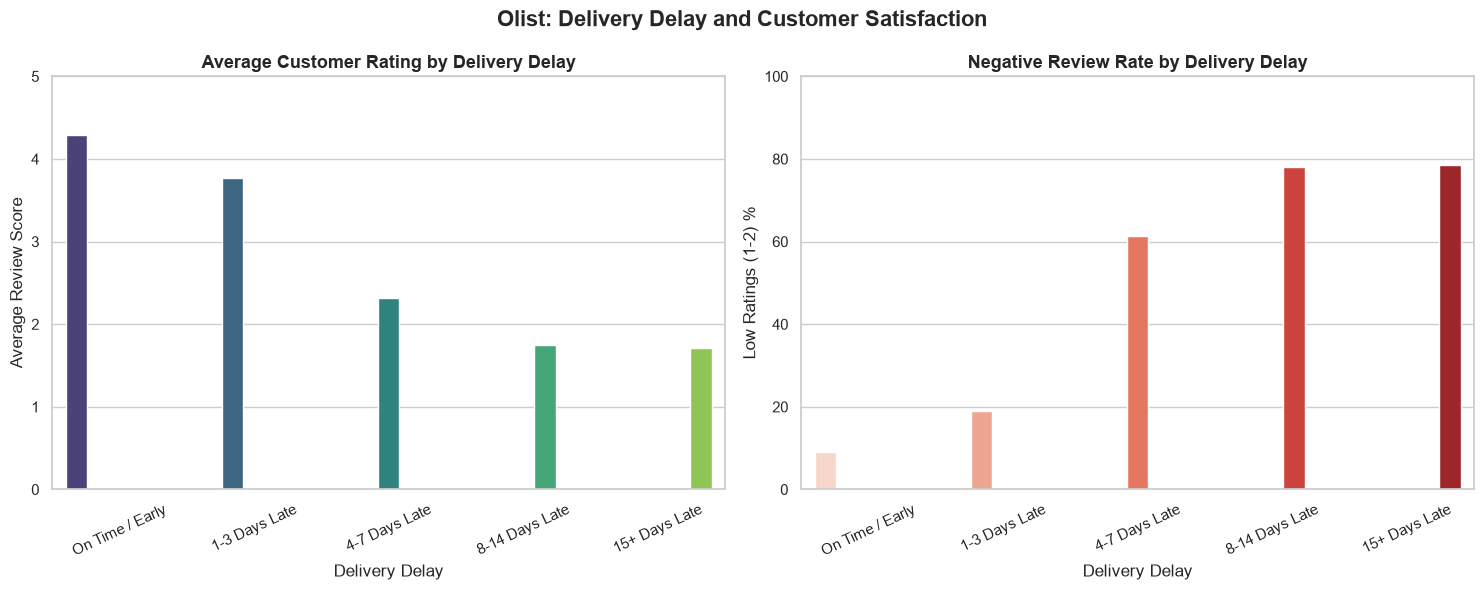

In [85]:
# %% DELIVERY DELAY IMPACT VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Average rating
sns.barplot(
    data=delay_summary,
    x="delay_group",
    y="average_rating",
    hue="delay_group",
    palette="viridis",
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Average Customer Rating by Delivery Delay",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Delivery Delay")
axes[0].set_ylabel("Average Review Score")
axes[0].set_ylim(0, 5)
axes[0].tick_params(axis="x", rotation=25)

# Chart 2: Negative rating percentage
sns.barplot(
    data=delay_summary,
    x="delay_group",
    y="low_rating_pct",
    hue="delay_group",
    palette="Reds",
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Negative Review Rate by Delivery Delay",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Delivery Delay")
axes[1].set_ylabel("Low Ratings (1-2) %")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=25)

plt.suptitle(
    "Olist: Delivery Delay and Customer Satisfaction",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Delivery Delays and Customer Satisfaction

An analysis of reviewed orders with valid delivery-delay data revealed a strong association between delivery delays and customer dissatisfaction. The negative-review rate (1-2 stars) increased from approximately **9% for on-time or early deliveries to 61% for orders delayed by 4-7 days**, reaching nearly **79% for delays exceeding 8 days**. Average review ratings also declined as delays increased.

**Business implication:** Delivery reliability is a key area for operational improvement. The business should investigate carrier performance, identify the causes of significant delays, and consider proactive customer communication when deliveries are at risk. These findings show an association rather than establishing causation.

In [86]:
# %% Seller Performance Analysis

# Keep delivered orders and their delivery metrics
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Attach seller information to individual order items
seller_items = order_items.merge(
    sellers,
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Attach delivery information to each order item
seller_items = seller_items.merge(
    delivered_orders[
        [
            "order_id",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "delivery_days",
            "delivery_performance"
        ]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Seller-level performance metrics
seller_performance = (
    seller_items.groupby("seller_id")
    .agg(
        delivered_item_count=("order_item_id", "count"),
        unique_orders=("order_id", "nunique"),
        product_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        avg_delivery_days=("delivery_days", "mean"),
        late_item_records=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

seller_performance["late_item_rate_pct"] = (
    seller_performance["late_item_records"]
    / seller_performance["delivered_item_count"]
    * 100
)

seller_performance = seller_performance.sort_values(
    "product_revenue", ascending=False
)

print("Seller performance shape:", seller_performance.shape)
display(seller_performance.head(10).round(2))

Seller performance shape: (2970, 8)


,seller_id,delivered_item_count,unique_orders,product_revenue,freight_revenue,avg_delivery_days,late_item_records,late_item_rate_pct
834,4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,226987.93,20019.13,15.01,133,11.59
982,53243585a1d6dc2643021fd1853d8905,400,348,217940.44,12856.58,13.37,16,4.00
858,4a3ca9315b744ce9f8e9374361493884,1949,1772,196882.12,34338.31,14.42,214,10.98
2903,fa1c13f2614d7b5c4749cbc52fecda94,579,578,190917.14,9916.36,13.34,59,10.19
1480,7c67e1448b00f6e969d365cea6b010ab,1355,973,186570.05,51236.64,22.39,130,9.59
1504,7e93a43ef30c4f03f38b393420bc753a,322,319,165981.49,5992.06,11.34,18,5.59
2543,da8622b14eb17ae2831f4ac5b9dab84a,1548,1311,159816.87,24889.91,11.17,113,7.30
1450,7a67c85e85bb2ce8582c35f2203ad736,1155,1145,139658.69,20619.83,11.17,68,5.89
188,1025f0e2d44d7041d6cf58b6550e0bfa,1420,910,138208.56,33716.40,12.05,131,9.23
1758,955fee9216a65b617aa5c0531780ce60,1472,1261,131836.71,24769.77,10.74,119,8.08


Let's add a minimum-volume filter and identify sellers with the highest and lowest late rates among sellers with at least 100 delivered item records. This reduces the chance of highlighting a seller based on a tiny sample.

In [87]:
# %% Compare Seller Delivery Performance

# Keep sellers with a reasonable number of delivered item records
reliable_sellers = seller_performance[
    seller_performance["delivered_item_count"] >= 100
].copy()

# Highest late-item rates
worst_late_rates = reliable_sellers.sort_values(
    "late_item_rate_pct", ascending=False
).head(10)

# Lowest late-item rates
best_late_rates = reliable_sellers.sort_values(
    "late_item_rate_pct", ascending=True
).head(10)

cols = [
    "seller_id",
    "delivered_item_count",
    "unique_orders",
    "product_revenue",
    "avg_delivery_days",
    "late_item_rate_pct"
]

print("Number of sellers with at least 100 delivered item records:",
      len(reliable_sellers))

print("\n10 HIGHEST LATE-ITEM RATES")
display(worst_late_rates[cols].round(2))

print("\n10 LOWEST LATE-ITEM RATES")
display(best_late_rates[cols].round(2))

Number of sellers with at least 100 delivered item records: 236

10 HIGHEST LATE-ITEM RATES


,seller_id,delivered_item_count,unique_orders,product_revenue,avg_delivery_days,late_item_rate_pct
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,104,96,8646.90,16.94,25.00
79,06a2c3af7b3aee5d69171b0e14f0ee87,402,389,36097.98,17.74,23.63
2404,cd68562d3f44870c08922d380acae552,129,122,18119.70,16.78,20.16
323,1ca7077d890b907f89be8c954a02686a,127,108,12474.64,15.03,19.69
1606,88460e8ebdecbfecb5f9601833981930,300,246,31320.40,18.27,19.67
2657,e5a3438891c0bfdb9394643f95273d8e,247,216,7549.96,15.38,18.22
1532,8160255418d5aaa7dbdc9f4c64ebda44,424,380,46368.39,16.78,17.92
2448,d20b021d3efdf267a402c402a48ea64b,102,86,3922.30,16.66,17.65
203,11bfa66332777660bd0640ee84d47006,102,76,3925.87,16.17,17.65
513,2c9e548be18521d1c43cde1c582c6de8,171,124,6013.56,13.73,16.96



10 LOWEST LATE-ITEM RATES


,seller_id,delivered_item_count,unique_orders,product_revenue,avg_delivery_days,late_item_rate_pct
2924,fc906263ca5083d09dce42fe02247800,117,112,4417.90,9.35,0.00
145,0bae85eb84b9fb3bd773911e89288d54,145,136,7433.56,10.27,0.69
1544,822166ed1e47908f7cfb49946d03c726,108,69,3714.83,13.87,0.93
981,530ec6109d11eaaf87999465c6afee01,101,94,12682.11,10.71,0.99
212,12b9676b00f60f3b700e83af21824c0e,133,133,26376.00,15.05,1.50
170,0ea22c1cfbdc755f86b9b54b39c16043,265,234,10592.10,11.02,1.51
593,33a6f4b1e7cdc205511e76ba1b6e0186,126,105,10295.01,8.54,1.59
1275,6c7d50c24b3ccd2fd83b44d8bb34e073,126,112,8445.96,12.14,1.59
463,289cdb325fb7e7f891c38608bf9e0962,125,109,13410.55,6.66,1.60
1654,8c16d1f32a54d92897cc437244442e1b,118,108,5642.60,10.98,1.69


## Key findings
- Delivery performance varies significantly: the highest-rate seller has 25% late item records, while the lowest-rate seller has none recorded as late.
- The highest-rate seller deserves investigation: seller 06a2c3af… has a 23.63% late rate across 402 item records, so the result isn't limited to a small-volume seller.
- Low late rates don't automatically mean the best overall performance: for example, seller 12b9676b… has a 1.50% late rate but an average delivery time of 15.05 days. Timeliness and speed are related but different metrics.

Right now, late_item_rate_pct counts item records, not unique seller-order combinations. If a seller supplies multiple items in one delayed order, that order can count several times.

In [88]:
# %% Seller Performance — Unique Seller-Order Metrics

# One row per seller per delivered order
seller_order_delivery = (
    seller_items[
        [
            "seller_id",
            "order_id",
            "delivery_days",
            "delivery_performance"
        ]
    ]
    .drop_duplicates(subset=["seller_id", "order_id"])
)

# Aggregate delivery performance at seller-order level
seller_delivery_metrics = (
    seller_order_delivery.groupby("seller_id")
    .agg(
        seller_orders=("order_id", "nunique"),
        avg_order_delivery_days=("delivery_days", "mean"),
        late_orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

seller_delivery_metrics["late_order_rate_pct"] = (
    seller_delivery_metrics["late_orders"]
    / seller_delivery_metrics["seller_orders"]
    * 100
)

# Combine delivery metrics with existing seller revenue metrics
seller_comparison = seller_performance.drop(
    columns=[
        "unique_orders",
        "avg_delivery_days",
        "late_item_records",
        "late_item_rate_pct"
    ],
    errors="ignore"
).merge(
    seller_delivery_metrics,
    on="seller_id",
    how="left",
    validate="one_to_one"
)

# Compare sellers with at least 100 unique seller-orders
reliable_seller_comparison = seller_comparison[
    seller_comparison["seller_orders"] >= 100
].copy()

print(
    "Sellers with at least 100 unique seller-orders:",
    len(reliable_seller_comparison)
)

print("\nHighest late-order rates")
display(
    reliable_seller_comparison
    .sort_values("late_order_rate_pct", ascending=False)
    [[
        "seller_id",
        "seller_orders",
        "product_revenue",
        "avg_order_delivery_days",
        "late_orders",
        "late_order_rate_pct"
    ]]
    .head(10)
    .round(2)
)

print("\nLowest late-order rates")
display(
    reliable_seller_comparison
    .sort_values("late_order_rate_pct", ascending=True)
    [[
        "seller_id",
        "seller_orders",
        "product_revenue",
        "avg_order_delivery_days",
        "late_orders",
        "late_order_rate_pct"
    ]]
    .head(10)
    .round(2)
)

Sellers with at least 100 unique seller-orders: 210

Highest late-order rates


,seller_id,seller_orders,product_revenue,avg_order_delivery_days,late_orders,late_order_rate_pct
65,06a2c3af7b3aee5d69171b0e14f0ee87,389,36097.98,17.73,90,23.14
219,1ca7077d890b907f89be8c954a02686a,108,12474.64,15.54,24,22.22
77,88460e8ebdecbfecb5f9601833981930,246,31320.40,17.80,48,19.51
387,e5a3438891c0bfdb9394643f95273d8e,216,7549.96,15.66,40,18.52
135,cd68562d3f44870c08922d380acae552,122,18119.70,16.26,22,18.03
40,8160255418d5aaa7dbdc9f4c64ebda44,380,46368.39,16.25,63,16.58
489,2c9e548be18521d1c43cde1c582c6de8,124,6013.56,13.68,20,16.13
314,dd7ddc04e1b6c2c614352b383efe2d36,121,9148.61,15.02,19,15.70
21,f7ba60f8c3f99e7ee4042fdef03b70c4,218,68070.00,13.41,34,15.60
207,431af27f296bc6519d890aa5a05fdb11,116,12974.60,17.23,18,15.52



Lowest late-order rates


,seller_id,seller_orders,product_revenue,avg_order_delivery_days,late_orders,late_order_rate_pct
615,fc906263ca5083d09dce42fe02247800,112,4417.90,9.40,0,0.00
396,0bae85eb84b9fb3bd773911e89288d54,136,7433.56,10.28,1,0.74
510,8c16d1f32a54d92897cc437244442e1b,108,5642.60,11.00,1,0.93
91,12b9676b00f60f3b700e83af21824c0e,133,26376.00,15.05,2,1.50
164,229c3efbfb0ea2058de4ccdfbc3d784a,118,15479.00,10.76,2,1.69
270,0ea22c1cfbdc755f86b9b54b39c16043,234,10592.10,11.03,4,1.71
340,6c7d50c24b3ccd2fd83b44d8bb34e073,112,8445.96,12.27,2,1.79
194,289cdb325fb7e7f891c38608bf9e0962,109,13410.55,6.73,2,1.83
108,612170e34b97004b3ba37eae81836b4c,107,23065.02,10.99,2,1.87
275,33a6f4b1e7cdc205511e76ba1b6e0186,105,10295.01,8.50,2,1.90


This gives us a fairer comparison of late deliveries across sellers. It still measures the delivery outcome of orders involving each seller, rather than proving who was responsible for the delay.

## The key findings
Highest late-order rate
23.14%
Seller 06a2c3af…
90 late orders out of 389

Lowest late-order rate
0.00%
Seller fc906263…
0 late orders out of 112



- The highest-rate seller is worth investigating first. Seller 06a2c3af… has 90 late orders, so the 23.14% rate is based on a substantial number of orders.
- The difference between sellers is large. Among the sellers shown, late-order rates range from 0% to 23.14%.
- Revenue and reliability are separate dimensions. Seller f7ba60f8… generated R$68,070 in product revenue with a 15.60% late-order rate. Revenue alone isn't enough to assess seller performance.
- A zero observed late rate isn't a guarantee. The seller with 112 orders and no recorded late deliveries looks promising, but we'd need to account for destination, carrier, and order mix before calling it the best seller.

## Let's visualize all 210 sellers

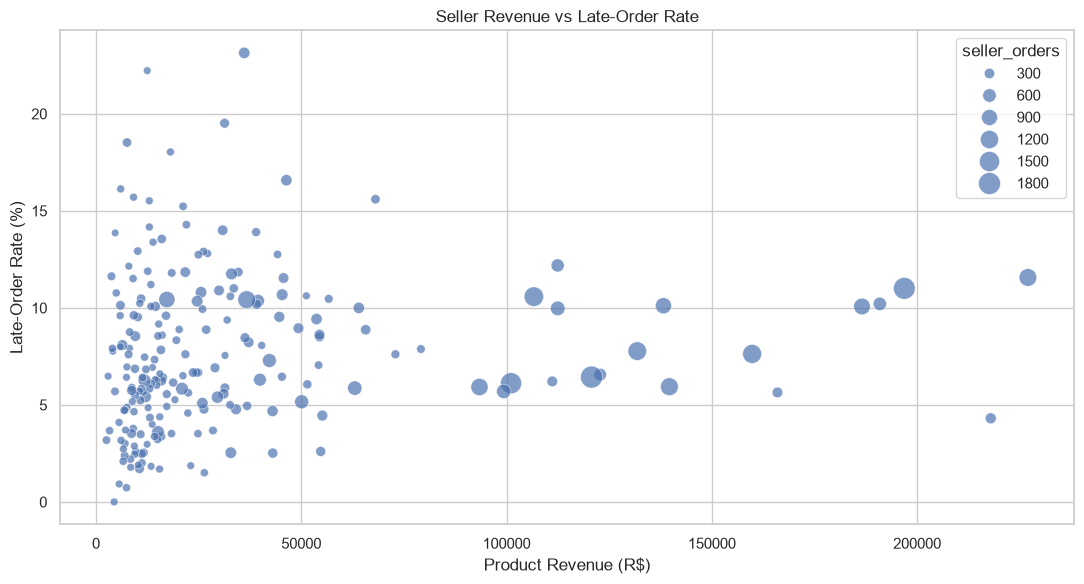

In [89]:
# %% Seller Revenue vs Delivery Reliability

import matplotlib.pyplot as plt
import seaborn as sns

plot_data = reliable_seller_comparison.dropna(
    subset=["product_revenue", "late_order_rate_pct"]
).copy()

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=plot_data,
    x="product_revenue",
    y="late_order_rate_pct",
    size="seller_orders",
    sizes=(30, 250),
    alpha=0.7
)

plt.title("Seller Revenue vs Late-Order Rate")
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Late-Order Rate (%)")
plt.tight_layout()
plt.show()

## What the chart tells us
- Most sellers cluster below R$50,000 in product revenue. Their late-order rates vary considerably, with many around 3–10% and some above 15%.
- Higher revenue doesn't guarantee better delivery reliability. Several high-revenue sellers have late-order rates around 6–12%.
- Some lower-revenue sellers have serious delivery issues. A few have late-order rates above 20%, making them worth investigating even though their revenue is relatively low.
- The largest sellers generally appear around 5–12% late orders in this chart, although there are exceptions.

**The key business takeaway**: seller performance should be evaluated using both commercial contribution and delivery reliability, rather than revenue alone.

**One important limitation**: this chart doesn't prove that revenue and late-order rates are correlated. We'd need a statistical check to quantify that relationship.

In [90]:
# %% Payment Behavior Analysis

# Summary by payment type
payment_type_summary = (
    order_payments.groupby("payment_type")
    .agg(
        payment_records=("payment_type", "size"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        avg_payment_value=("payment_value", "mean"),
        avg_installments=("payment_installments", "mean")
    )
    .reset_index()
)

payment_type_summary["revenue_share_pct"] = (
    payment_type_summary["total_payment_value"]
    / payment_type_summary["total_payment_value"].sum()
    * 100
)

payment_type_summary = payment_type_summary.sort_values(
    "total_payment_value", ascending=False
)

print("PAYMENT TYPE SUMMARY")
display(payment_type_summary.round(2))

PAYMENT TYPE SUMMARY


,payment_type,payment_records,unique_orders,total_payment_value,avg_payment_value,avg_installments,revenue_share_pct
1,credit_card,76795,76505,12542084.19,163.32,3.51,78.34
0,boleto,19784,19784,2869361.27,145.03,1.00,17.92
4,voucher,5775,3866,379436.87,65.70,1.00,2.37
2,debit_card,1529,1528,217989.79,142.57,1.00,1.36
3,not_defined,3,3,0.00,0.00,1.00,0.00


## Payment behavior - key findings
Credit card share
78.34%
R$12.54 million in payment value

Boleto share
17.92%
R$2.87 million in payment value



- Credit cards lead: 76,505 unique orders used credit-card payment records, with an average payment record value of R$163.32.
- Installments are significant: Credit-card records average 3.51 installments, compared with 1.00 for boleto and debit card.

- Vouchers have a smaller role: They account for 2.37% of payment value, and their 5,775 payment records correspond to 3,866 distinct orders. This suggests some orders have multiple voucher records.
- Debit cards contribute relatively little: They represent 1.36% of payment value in this dataset.

## Next: analyzing installment behavior

In [91]:
# %% Credit Card Installment Analysis

credit_card_payments = order_payments[
    order_payments["payment_type"] == "credit_card"
].copy()

installment_summary = (
    credit_card_payments.groupby("payment_installments")
    .agg(
        payment_records=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        avg_payment_value=("payment_value", "mean")
    )
    .reset_index()
    .sort_values("payment_installments")
)

installment_summary["payment_value_share_pct"] = (
    installment_summary["total_payment_value"]
    / installment_summary["total_payment_value"].sum()
    * 100
)

print("CREDIT CARD INSTALLMENT SUMMARY")
display(installment_summary.round(2))

CREDIT CARD INSTALLMENT SUMMARY


,payment_installments,payment_records,unique_orders,total_payment_value,avg_payment_value,payment_value_share_pct
0,0,2,2,188.63,94.32,0.00
1,1,25455,25407,2440445.43,95.87,19.46
2,2,12413,12389,1579283.03,127.23,12.59
3,3,10461,10443,1491103.80,142.54,11.89
4,4,7098,7088,1163907.61,163.98,9.28
5,5,5239,5234,961174.30,183.47,7.66
6,6,3920,3916,822611.81,209.85,6.56
7,7,1626,1623,305157.39,187.67,2.43
8,8,4268,4253,1313423.34,307.74,10.47
9,9,644,644,131015.92,203.44,1.04


Let's rebuild the summary cleanly and exclude zero-installment records from the main installment comparison. We should inspect those separately rather than silently treating them as a normal installment option.

In [92]:
# %% Clean Credit Card Installment Analysis

credit_card_payments = order_payments[
    order_payments["payment_type"] == "credit_card"
].copy()

# Inspect unusual installment counts first
print("Installment count values:")
display(
    credit_card_payments["payment_installments"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRecords with zero or missing installments:")
display(
    credit_card_payments[
        credit_card_payments["payment_installments"].isna()
        | (credit_card_payments["payment_installments"] <= 0)
    ].head(10)
)

# Analyze positive installment counts only
valid_installments = credit_card_payments[
    credit_card_payments["payment_installments"] > 0
].copy()

installment_summary = (
    valid_installments.groupby("payment_installments")
    .agg(
        payment_records=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        avg_payment_value=("payment_value", "mean")
    )
    .reset_index()
    .sort_values("payment_installments")
)

installment_summary["payment_value_share_pct"] = (
    installment_summary["total_payment_value"]
    / installment_summary["total_payment_value"].sum()
    * 100
)

print("\nCLEAN INSTALLMENT SUMMARY")
display(installment_summary.round(2))

Installment count values:


payment_installments
0         2
1     25455
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64


Records with zero or missing installments:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94



CLEAN INSTALLMENT SUMMARY


,payment_installments,payment_records,unique_orders,total_payment_value,avg_payment_value,payment_value_share_pct
0,1,25455,25407,2440445.43,95.87,19.46
1,2,12413,12389,1579283.03,127.23,12.59
2,3,10461,10443,1491103.80,142.54,11.89
3,4,7098,7088,1163907.61,163.98,9.28
4,5,5239,5234,961174.30,183.47,7.66
5,6,3920,3916,822611.81,209.85,6.56
6,7,1626,1623,305157.39,187.67,2.43
7,8,4268,4253,1313423.34,307.74,10.47
8,9,644,644,131015.92,203.44,1.04
9,10,5328,5315,2211577.34,415.09,17.63


1. Final installment findings
Most common option
1 installment
25,407 unique orders
19.46% of valid installment payment value

Notable installment option
10 installments
5,315 unique orders
17.63% of valid installment payment value



Other useful findings:
- 8 installments account for 10.47% of payment value.
- 1–3 installments combined account for approximately 43.94% of valid installment payment value.
- The average payment record value rises from R$95.87 for one installment to R$415.09 for ten installments. This is consistent with larger payment amounts being spread across more installments, but it doesn't prove that installment choice caused customers to spend more.
- Two records have zero installments despite nonzero payment values. Keep them flagged as data-quality exceptions rather than changing them to one installment without evidence.
One nuance: the percentages above describe payment value, not the percentage of customers choosing each installment count. An order may have multiple payment records.

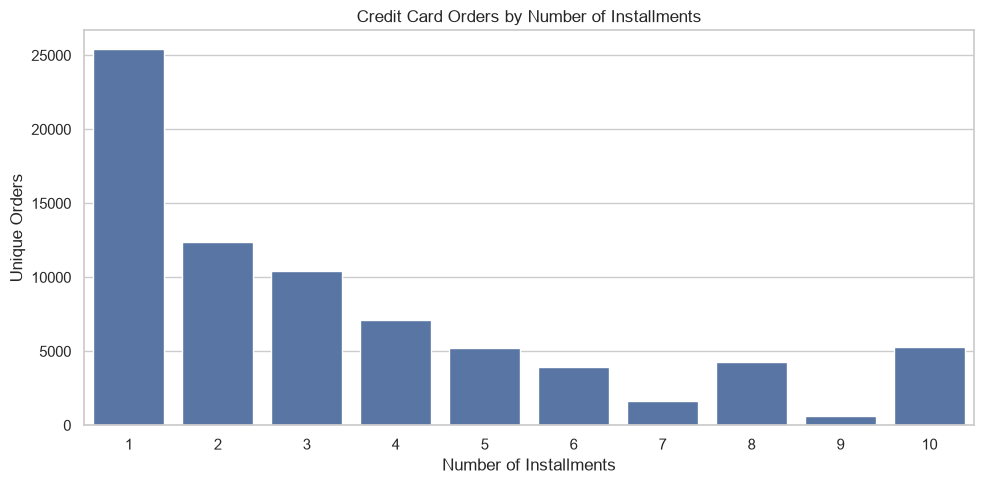

In [93]:
# %% Credit Card Installment Distribution

import matplotlib.pyplot as plt
import seaborn as sns

installment_plot = installment_summary[
    installment_summary["payment_installments"] <= 10
].copy()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=installment_plot,
    x="payment_installments",
    y="unique_orders"
)

plt.title("Credit Card Orders by Number of Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Unique Orders")
plt.tight_layout()
plt.show()

In [94]:
print("========== FINAL KPI CHECK ==========")

print("Total orders:", len(orders))
print("Delivered orders:", (orders["order_status"] == "delivered").sum())
print("Canceled orders:", (orders["order_status"] == "canceled").sum())

print("\nDelivered product revenue:",
      round(delivered_financial["item_revenue"].sum(), 2))

print("Delivered freight revenue:",
      round(delivered_financial["freight_revenue"].sum(), 2))

print("Delivered total order value:",
      round(delivered_financial["order_total"].sum(), 2))

print("\nUnique delivered customers:",
      delivered_financial["customer_unique_id"].nunique()
      if "customer_unique_id" in delivered_financial.columns
      else "Customer ID not merged into this table")

print("\nReview analysis rows:", len(review_analysis))
print("Sellers with at least 100 seller-orders:",
      len(reliable_seller_comparison))

========== FINAL KPI CHECK ==========
Total orders: 99441
Delivered orders: 96478
Canceled orders: 625

Delivered product revenue: 13221498.11
Delivered freight revenue: 2198275.64
Delivered total order value: 15419773.75

Unique delivered customers: Customer ID not merged into this table

Review analysis rows: 95832
Sellers with at least 100 seller-orders: 210


# Final Business Insights & Recommendations

## 1. Sales Performance
Olist recorded 99,441 orders, including 96,478 delivered orders. Delivered orders generated R$13.22 million in product revenue and R$2.20 million in freight revenue, totaling R$15.42 million in order value.

**Recommendation:** Monitor product revenue and freight separately to understand sales performance and delivery-cost contributions.

## 2. Customer Retention
The analysis identified 93,358 unique customers among delivered orders. Most purchased only once, while repeat customers represented a small portion of the customer base but generated a higher average customer revenue.

**Recommendation:** Test customer retention campaigns, personalized recommendations, and post-purchase engagement to encourage repeat purchases.

## 3. Delivery Performance & Customer Satisfaction
Customer ratings declined substantially as delivery delays increased. Orders delivered on time or early had an average rating of 4.29, compared with 1.71 for orders delayed by 15 or more days.

**Recommendation:** Prioritize late-delivery prevention, proactive customer communication, and investigation of recurring logistics problems.

## 4. Regional Performance
São Paulo was the largest state by delivered product revenue, contributing approximately 38.33% of delivered product revenue. Delivery times and late-order rates varied across states.

**Recommendation:** Review regional logistics performance and identify opportunities to improve delivery reliability in states with consistently high delay rates.

## 5. Seller Performance
Seller late-order rates varied considerably, even among sellers with at least 100 seller-orders.

**Recommendation:** Investigate consistently high-delay sellers, compare their regional and order profiles, and share practices from stronger performers.

## 6. Payment Behavior
Credit cards accounted for approximately 78.34% of recorded payment value. Installment payments were common, with one-installment payments the most frequent installment category.

**Recommendation:** Monitor payment-method preferences and installment behavior when evaluating checkout experience and payment strategy.

## Limitations
These findings describe observed patterns and associations; they do not establish causation. Seller and regional comparisons may be influenced by product mix, geography, shipping providers, and order characteristics. Recommendations should be validated through further analysis or controlled experiments.

In [95]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
]

delivered_customer_analysis = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

print("Delivered orders:", len(delivered_customer_analysis))
print(
    "Unique customer identities:",
    delivered_customer_analysis["customer_unique_id"].nunique()
)
print(
    "Missing customer identities:",
    delivered_customer_analysis["customer_unique_id"].isna().sum()
)

Delivered orders: 96478
Unique customer identities: 93358
Missing customer identities: 0
